# 15 — Eventi su clip NBA (v2): palla ad alta risoluzione, tagli di scena, lavagna automatica e semi-automatica

Seconda versione del modulo eventi, pensata per **clip NBA registrate** (dominio del detector) e costruita sugli errori visti nel notebook 14:

| Problema visto nel 14 | Soluzione nel 15 |
|---|---|
| Palla trovata solo nel 37% dei frame, scambiata con altro | Detection a **risoluzione piena** (`DET_IMGSZ = 1280`) + **tracker della palla** (filtro di Kalman con finestra di ricerca): si accetta solo una palla coerente con il moto precedente |
| La palla "schizza" | Niente interpolazione lunga: si riempiono solo buchi ≤ 4 frame tra punti accettati |
| Le riprese NBA hanno **tagli di inquadratura** e replay | Rilevamento automatico dei tagli: tracker, possesso ed eventi ripartono da zero a ogni taglio; si possono escludere intervalli (replay) |
| Video lunghi non entrano in memoria | I frame vengono letti dal video a ogni passaggio, non tenuti tutti in RAM |
| Eventi automatici inaffidabili | Oltre agli eventi automatici, **modalità semi-automatica**: gli eventi li scrivi tu in un CSV (tempo, tipo, ID dei giocatori visti nel video), posizioni e squadre restano automatiche. Lo stesso CSV fa da **riferimento** per valutare gli eventi automatici |

Output in `events_nba/<clip>/`, compreso un **video diagnostico** con tutte le palle candidate (grigio) e quella accettata (giallo).
Runtime: **Colab GPU T4**. Servono `models/yolo11m_ft.pt` (salvato dal notebook 10) e il Secret `ROBOFLOW_API_KEY`.

In [1]:
%pip install -q ultralytics trackers supervision inference "git+https://github.com/roboflow/sports.git@feat/basketball"
%pip uninstall -y -q torchaudio   # versione CUDA diversa da PyTorch: fa crashare l'import di sports (non serve)
# dopo il pip: Runtime -> Riavvia sessione, poi esegui dalla cella successiva

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing

In [1]:
import sys
if 'triton' not in sys.modules: sys.modules['triton'] = None     # evita il crash di triton su Colab

# ==== SETUP COMUNE (uguale in tutti i notebook) ====
import sys, os
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/Tesi_Basket')   # progetto su Drive
    FAST = Path('/content/fast')                                 # disco locale Colab (veloce)
else:
    ROOT = Path(r'F:\Tesi Basket')                               # progetto in locale
    FAST = ROOT / '_cache'
FAST.mkdir(parents=True, exist_ok=True)
assert ROOT.is_dir(), f'Cartella del progetto non trovata: {ROOT}'
print('Progetto:', ROOT)

import faulthandler; faulthandler.enable()
import json, time, subprocess
import numpy as np, pandas as pd, cv2
import supervision as sv
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

Mounted at /content/drive
Progetto: /content/drive/MyDrive/Tesi_Basket


## 0. (Una volta sola) FPS del video lungo e taglio delle clip di prova

Le clip vengono prese dalla **zona di test** del notebook 16 (frame 28800-41140 di `nba_finals2016.mp4`, mai usati per l'addestramento del detector della palla). La cella legge gli FPS e converte da sola i frame in secondi, quindi non devi fare calcoli. Se le clip esistono già, non fa niente: puoi saltarla.

In [2]:
import shutil
SRC = ROOT / 'videos' / 'nba_finals2016.mp4'
OUT_DIR = ROOT / 'videos' / 'eventi'; OUT_DIR.mkdir(parents=True, exist_ok=True)
TEST_F0, TEST_F1 = 28800, 41140          # zona di test del notebook 16 (in frame)
CLIP_S = 60                              # durata di ogni clip (secondi)

cap = cv2.VideoCapture(str(SRC)); fps_src = cap.get(cv2.CAP_PROP_FPS); cap.release()
z0, z1 = TEST_F0 / fps_src, TEST_F1 / fps_src
mmss = lambda t: f'{int(t // 60)}:{t % 60:04.1f}'
print(f'FPS di {SRC.name}: {fps_src:.2f}  ->  zona di test {mmss(z0)} - {mmss(z1)} ({z1 - z0:.0f} s)')

starts = np.linspace(z0 + 5, z1 - CLIP_S - 5, 3)   # 3 clip distribuite nella zona
TAGLI = [(f'finals2016_az{i + 1}', a, a + CLIP_S) for i, a in enumerate(starts)]
assert shutil.which('ffmpeg'), 'ffmpeg mancante'
for name, a, b in TAGLI:
    dst = OUT_DIR / f'{name}.mp4'
    print(f'{name}: {mmss(a)} - {mmss(b)}', '(esiste già)' if dst.is_file() else '')
    if dst.is_file(): continue
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-ss', f'{a:.2f}', '-to', f'{b:.2f}', '-i', str(SRC),
                    '-c:v', 'libx264', '-crf', '18', '-an', str(dst)], check=True)
print('Clip in', OUT_DIR)

FPS di nba_finals2016.mp4: 29.97  ->  zona di test 16:01.0 - 22:52.7 (412 s)
finals2016_az1: 16:06.0 - 17:06.0 (esiste già)
finals2016_az2: 18:56.8 - 19:56.8 (esiste già)
finals2016_az3: 21:47.7 - 22:47.7 (esiste già)
Clip in /content/drive/MyDrive/Tesi_Basket/videos/eventi


## 1. Configurazione

Metti la clip in `videos/` su Drive. Consigli per la registrazione: partita intera o *condensed game* (non highlights), inquadratura larga, 1280×720 o più, 30 fps, senza mouse o sovrimpressioni del player. Se la clip contiene replay, indicali in `ESCLUDI`.

In [3]:
VIDEO = ROOT / 'videos' / 'eventi' / 'finals2016_az4.mp4'   # <-- la clip da analizzare (az1, az2, az3)
START_S, END_S = 0, None                        # tratto da analizzare (secondi); None = fino alla fine
ESCLUDI = [(0, 13.2)]                          # intervalli da ignorare (primi piani, replay); az1: primi piani 9-14.5 s
LEAGUE_NAME = 'nba'                             # 'nba' oppure 'fiba'

WORK_W = 1280                                   # larghezza di lavoro (i video più grandi vengono ridotti)
DET_WEIGHTS = ROOT / 'models' / 'yolo11m_ft.pt'      # su clip NBA (in-domain) YOLO11m è il migliore in E1 ed è 3,5x più veloce
DET_IMGSZ = 640                                 # giocatori: 640 è il migliore in E4 (la palla ora la fa il detector dedicato a 1280)
BALL_WEIGHTS = ROOT / 'models' / 'ball_detector.pt'   # detector dedicato alla palla (notebook 16); se manca si usa la palla del detector principale
BALL_IMGSZ = 1280
DET_CONF = 0.05
COURT_MODEL_ID = 'basketball-court-detection-2/14'
HOMO_EVERY = 3
CUT_THR = 0.55                                  # somiglianza minima tra frame consecutivi; sotto = taglio di scena
SCORE_BOXES = {'L': (0.426, 0.799, 0.469, 0.847), 'R': (0.598, 0.799, 0.642, 0.847)}   # cifre del punteggio nel tabellone ESPN (frazioni di larghezza/altezza)
SCORE_LOGO = (0.219, 0.799, 0.299, 0.847)      # logo del tabellone: serve a capire se il tabellone è visibile
SCORE_SIDE = {0: 'L', 1: 'R'}                  # squadra 0 (scura, CLE) a sinistra nel tabellone, squadra 1 (chiara, GS) a destra
SCORE_THR = 0.035; SCORE_HOLD_S = 1.5; SCORE_FRAC = 0.8; MADE_WINDOW_S = 6.0   # cambio del punteggio stabile per 1,5 s, entro 6 s dal tiro
OUT_MARGIN_FT = 3.0; OUT_FRAC = 0.6            # persona fuori dal campo (oltre 3 ft dalle linee) per il 60% del tempo: panchina/tifosi/staff
TRACK_REFEREES = False                           # traccia anche i box "referee": il detector chiama spesso arbitro chi ha la maglia scura; si decide poi a livello di traccia
OCC_IOU = 1.0                                   # colore della maglia letto solo quando il giocatore non è sovrapposto ad altri (se possibile)
MIN_SCENE_S = 1.0                               # tagli più vicini di così (dissolvenze) contano come uno solo
TRACK_BUFFER_S = 2.0                            # quanto il tracker "ricorda" un giocatore non visto prima di dargli un ID nuovo
FT_TO_M = 0.3048
STEAL_HELD_N = 5             # v3: palla vista DENTRO il box per almeno 5 frame, sia per chi perde sia per chi recupera
STEAL_GAP_S = 2.0            # v3: per le palle rubate il possesso di squadra continua anche dopo un taglio di scena (buco <= 2 s)


# tracce e squadre (come notebook 13/14)
INTERP_MAX_GAP = 20; DUP_IOU = 0.7; SPLIT_MIN_SAMPLES = 5; OUTLIER_K = 3.0
SCOREBOARD_REL = (0.00, 0.79, 0.82, 0.95)       # tabellone NBA in basso; None se non c'è

# palla (tracker di Kalman)
BALL_MIN_CONF = 0.15        # candidati palla considerati
BALL_INIT_CONF = 0.40       # confidenza per (ri)agganciare la palla
BALL_GATE = 0.05            # raggio di ricerca per frame di assenza (frazione della larghezza)
BALL_MAX_MISS = 8           # frame senza conferma dopo i quali la palla è persa
BALL_FILL = 4               # buchi riempiti tra punti accettati

# possesso ed eventi (come notebook 14 v2)
POSS_CONF = 0.30; POSS_RADIUS = 0.35; POSS_MIN = 5; POSS_LOST = 10
MIN_SEG_S = 0.4; STEAL_MIN_S = 1.5; PASS_MIN_M = 1.0; SWITCH_DIST_M = 1.0; PASS_MAX_GAP_S = 2.0
SHOT_MIN_FRAMES = 3; SHOT_WINDOW_S = 3.0; MADE_CONF = 0.75; MADE_MIN_FRAMES = 3   # su az1 "ball-in-basket" arriva a 0,69 anche sui tiri sbagliati
EVENT_TOL_S = 1.0
RIM_CONF = 0.30; RIM_MIN_FRAMES = 2; SHOT_LOOKBACK_S = 2.0   # tiro = la palla arriva vicino al ferro dopo aver lasciato un giocatore
PASS_FREE_FRAMES = 2; PASS_LONG_M = 4.0                     # passaggio/palla rubata: palla vista libera in volo, oppure distanza >= 4 m
PASS_SEEN_BEFORE_S = 0.5    # chi riceve deve essere già in campo da almeno 0,5 s (se "nasce" con la palla, era solo non rilevato)
PASS_MAX_BLIND_S = 0.5      # buco massimo senza vedere la palla tra i due possessi (se è più lungo non si può dire che sia un passaggio)
PASS_HOLD_S = 0.6           # se la palla non si vede in volo, chi riceve deve tenerla almeno 0,6 s
POSS_TIE = 0.15             # palla "in mezzo" a più giocatori: a parità di distanza si preferisce il compagno di chi l'aveva
REB_MAX_GAP_S = 3.0         # il rimbalzo può arrivare fino a 3 s dopo la fine del possesso del tiratore (palla in volo, cambi di telecamera)
REB_HOLD_FRAC = 0.25        # rimbalzo solo se la palla, quando è visibile, sta DENTRO il box del rimbalzista almeno nel 25% dei frame (non solo vicina)
REB_MIN_S = 1.0             # rimbalzo = prima squadra che tiene la palla almeno 1 s dopo il tiro (non chi la tocca per un attimo)
VIDEO_EVENTS = 'auto'       # eventi disegnati nel video: 'auto' (quelli del modello) o 'manuale'
SHOW_PASSES = True; PASS_SHOW_S = 2.0   # passaggi nel video: frecce che spariscono dopo 2 s (False = non disegnarli)
MADE_THROUGH = False        # True = in più la palla deve essere vista sotto il ferro (su az1 non distingue: anche i tiri sbagliati ricadono lì)

MANUAL = ROOT / 'annotations' / 'eventi_manuali.csv'   # eventi scritti a mano (lavagna semi-automatica + riferimento)
CLIP_ID = VIDEO.stem
OUT = ROOT / 'events_nba' / CLIP_ID; OUT.mkdir(parents=True, exist_ok=True)

cap = cv2.VideoCapture(str(VIDEO)); assert cap.isOpened(), f'Video non trovato: {VIDEO}'
FPS = cap.get(cv2.CAP_PROP_FPS) or 30.0; TOT = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
SRC_W, SRC_H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)); cap.release()
F0 = int(START_S * FPS); F1 = min(TOT, int(END_S * FPS)) if END_S else TOT
N = F1 - F0
W_IMG = min(WORK_W, SRC_W); H_IMG = int(round(SRC_H * W_IMG / SRC_W))
print(f'{CLIP_ID}: {SRC_W}x{SRC_H} a {FPS:.2f} fps -> analizzo {N} frame ({N / FPS:.1f} s) a {W_IMG}x{H_IMG}')
excluded = np.zeros(N, bool)
for a, b in ESCLUDI: excluded[max(0, int((a - START_S) * FPS)):max(0, int((b - START_S) * FPS))] = True

def frames_iter(step=1, wanted=None, desc=None):
    # legge i frame dal video uno alla volta (niente video intero in memoria)
    cap = cv2.VideoCapture(str(VIDEO))
    for _ in range(F0): cap.grab()
    for fi in tqdm(range(N), desc=desc, leave=False, disable=desc is None):
        ok, f = cap.read()
        if not ok: break
        if fi % step or (wanted is not None and fi not in wanted): continue
        yield fi, (cv2.resize(f, (W_IMG, H_IMG), interpolation=cv2.INTER_AREA) if f.shape[1] != W_IMG else f)
    cap.release()

finals2016_az4: 1280x720 a 29.97 fps -> analizzo 1800 frame (60.1 s) a 1280x720


## 2. Detection ad alta risoluzione, tagli di scena e tracking (BoT-SORT, riavviato a ogni taglio)

In [4]:
from ultralytics import YOLO, RTDETR
import trackers as T
model = RTDETR(str(DET_WEIGHTS)) if 'rtdetr' in str(DET_WEIGHTS).lower() else YOLO(str(DET_WEIGHTS))
NAMES = model.names

def iou_xyxy(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    ar = lambda r: (r[:, 2] - r[:, 0]) * (r[:, 3] - r[:, 1])
    return inter / (ar(a)[:, None] + ar(b)[None, :] - inter + 1e-9)

USE_BALL = BALL_WEIGHTS.is_file()
ball_model = YOLO(str(BALL_WEIGHTS)) if USE_BALL else None
BALL_ID = [i for i, n in NAMES.items() if n == 'ball'][0]
print('palla:', 'detector dedicato (notebook 16)' if USE_BALL else 'detector principale')
tag = f's{F0}_n{N}_w{W_IMG}_i{DET_IMGSZ}' + ('_ball' if USE_BALL else '')
dcache, ccache = OUT / f'detections_{tag}.npy', OUT / f'cuts_{tag}.json'
have_det = dcache.is_file() and ccache.is_file()
D = np.load(dcache) if have_det else None
det_by = {}
if have_det and len(D):
    D = D[np.argsort(D[:, 0], kind='stable')]; u, idx = np.unique(D[:, 0].astype(int), return_index=True)
    det_by = {int(k): a for k, a in zip(u, np.split(D, idx[1:]))}
PLAYER_IDS = [i for i, n in NAMES.items() if n.startswith('player') or (TRACK_REFEREES and n == 'referee')]
REF_ID = next((i for i, n in NAMES.items() if n == 'referee'), -1)
def nms_any(p, thr=0.5):
    # box "referee" tenuti solo se sulla stessa persona non c'è già un box "player" (il tracking dei giocatori resta come prima)
    if len(p) < 2: return p
    isr = p[:, 6].astype(int) == REF_ID
    if not isr.any() or isr.all(): return p
    M = iou_xyxy(p[isr, 1:5], p[~isr, 1:5])
    keep_r = M.max(1) <= thr
    return np.concatenate([p[~isr], p[isr][keep_r]])
rows_det, cuts, prev_h = [], [] if not have_det else json.loads(ccache.read_text()), None
rows_trk, tracker, scene = [], None, -1
def merge_cuts(c):
    out = []
    for x in sorted(c):
        if not out or x - out[-1] >= MIN_SCENE_S * FPS: out.append(x)
    return out
cuts = merge_cuts(cuts); cut_set = set(cuts)
import inspect
_bp = [k for k in inspect.signature(T.BoTSORTTracker).parameters if 'buffer' in k or 'lost' in k]
def new_tracker():
    kw = {_bp[0]: int(TRACK_BUFFER_S * FPS)} if _bp else {}
    return T.BoTSORTTracker(frame_rate=FPS, **kw)
print('memoria del tracker:', f'{_bp[0]} = {int(TRACK_BUFFER_S * FPS)} frame' if _bp else 'parametro non trovato (default)')
for fi, f in frames_iter(desc='detection + tracking'):
    if not have_det:
        small = cv2.cvtColor(cv2.resize(f, (160, 90)), cv2.COLOR_BGR2HSV)
        h = cv2.calcHist([small], [0, 1], None, [30, 16], [0, 180, 0, 256]); cv2.normalize(h, h)
        if prev_h is not None and cv2.compareHist(prev_h, h, cv2.HISTCMP_CORREL) < CUT_THR and (not cuts or fi - cuts[-1] >= MIN_SCENE_S * FPS): cuts.append(fi); cut_set.add(fi)
        prev_h = h
        r = model.predict(f, imgsz=DET_IMGSZ, conf=DET_CONF, iou=0.7, verbose=False)[0]
        d = np.column_stack([np.full(len(r.boxes), fi), r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy()])
        if USE_BALL:                                          # la palla viene dal detector dedicato
            rb = ball_model.predict(f, imgsz=BALL_IMGSZ, conf=0.05, verbose=False, max_det=10)[0]
            db = np.column_stack([np.full(len(rb.boxes), fi), rb.boxes.xyxy.cpu().numpy(), rb.boxes.conf.cpu().numpy(), np.full(len(rb.boxes), BALL_ID)])
            d = np.concatenate([d[d[:, 6].astype(int) != BALL_ID], db])
        rows_det.append(d); det_by[fi] = d
    if tracker is None or fi in cut_set:
        tracker = new_tracker(); scene += 1
    d = det_by.get(fi, np.zeros((0, 7)))
    p = d[np.isin(d[:, 6].astype(int), PLAYER_IDS)] if len(d) else d
    p = nms_any(p)
    tr = tracker.update(sv.Detections(xyxy=p[:, 1:5].astype(np.float32), confidence=p[:, 5].astype(np.float32),
                                      class_id=np.zeros(len(p), int)), frame=f)
    if len(tr) == 0: continue
    M = iou_xyxy(tr.xyxy, p[:, 1:5]) if len(p) else np.zeros((len(tr), 0))
    for k, (b, tid) in enumerate(zip(tr.xyxy, tr.tracker_id)):
        if tid is None or tid < 0: continue
        j = int(M[k].argmax()) if M.shape[1] else -1
        ok = j >= 0 and M[k, j] > 0.5
        rows_trk.append([fi, scene * 1000 + int(tid) + 1, *b, NAMES[int(p[j, 6])] if ok else 'player', float(p[j, 5]) if ok else np.nan])
if not have_det:
    D = np.concatenate(rows_det) if rows_det else np.zeros((0, 7)); np.save(dcache, D); ccache.write_text(json.dumps(cuts))
det = pd.DataFrame(D, columns=['frame', 'x1', 'y1', 'x2', 'y2', 'conf', 'cls'])
det['frame'] = det.frame.astype(int); det['name'] = det.cls.astype(int).map(NAMES).astype(str)
scene_of = np.zeros(N, int)
for c in cuts: scene_of[c:] += 1
tracks = pd.DataFrame(rows_trk, columns=['frame', 'track_id', 'x1', 'y1', 'x2', 'y2', 'cls', 'cls_conf'])
tracks = tracks[~excluded[tracks.frame.values]].reset_index(drop=True)

def interpolate(t, max_gap, cols=('x1', 'y1', 'x2', 'y2')):
    out = []
    for tid, g in t.groupby('track_id'):
        g = g.set_index('frame').reindex(range(int(g.frame.min()), int(g.frame.max()) + 1))
        miss = g.x1.isna(); run = (miss != miss.shift()).cumsum()
        g[list(cols)] = g[list(cols)].interpolate(limit_area='inside')
        keep = ~miss | (miss.groupby(run).transform('sum') <= max_gap)
        g = g[keep].copy(); g['track_id'] = tid; g['cls'] = g['cls'].fillna('interp')
        g.index.name = 'frame'; out.append(g.reset_index())
    return pd.concat(out, ignore_index=True)
tracks = interpolate(tracks, INTERP_MAX_GAP)
tracks['frame'] = tracks.frame.astype(int); tracks['track_id'] = tracks.track_id.astype(int)
print(f'tagli di scena: {len(cuts)} ({[round(c / FPS + START_S, 1) for c in cuts][:15]} s) | tracce: {tracks.track_id.nunique()}')
print(det[det.conf >= 0.3]['name'].value_counts().to_dict())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


/usr/local/lib/python3.13/dist-packages/deprecate/deprecation.py:319: FutureWarning: target=None is deprecated since `v0.8`; use `TargetMode.NOTIFY` instead. Will be removed in `v1.0`.
  return _callable_pack(source, _stacklevel + 1, _is_static)  # type: ignore[call-arg, arg-type]


palla: detector dedicato (notebook 16)
memoria del tracker: lost_track_buffer = 59 frame


detection + tracking:   0%|          | 0/1800 [00:00<?, ?it/s]

tagli di scena: 8 ([3.6, 4.6, 13.9, 32.6, 33.6, 40.4, 50.6, 57.2] s) | tracce: 111
{'player': 10612, 'referee': 6325, 'number': 3520, 'rim': 1271, 'ball': 1067, 'player-in-possession': 384, 'player-shot-block': 160, 'player-jump-shot': 155, 'ball-in-basket': 6, 'player-layup-dunk': 1}


## 3. Pulizia tracce, squadre e arbitro (come notebook 13/14)

colori maglia:   0%|          | 0/1800 [00:00<?, ?it/s]

campioni colore: 3380 | scartati perché sovrapposti: 0
tracce divise: 20 | tracce per squadra: {1: 47, 0: 44, -1: 26} | escluse: 26


foglio squadre:   0%|          | 0/1800 [00:00<?, ?it/s]

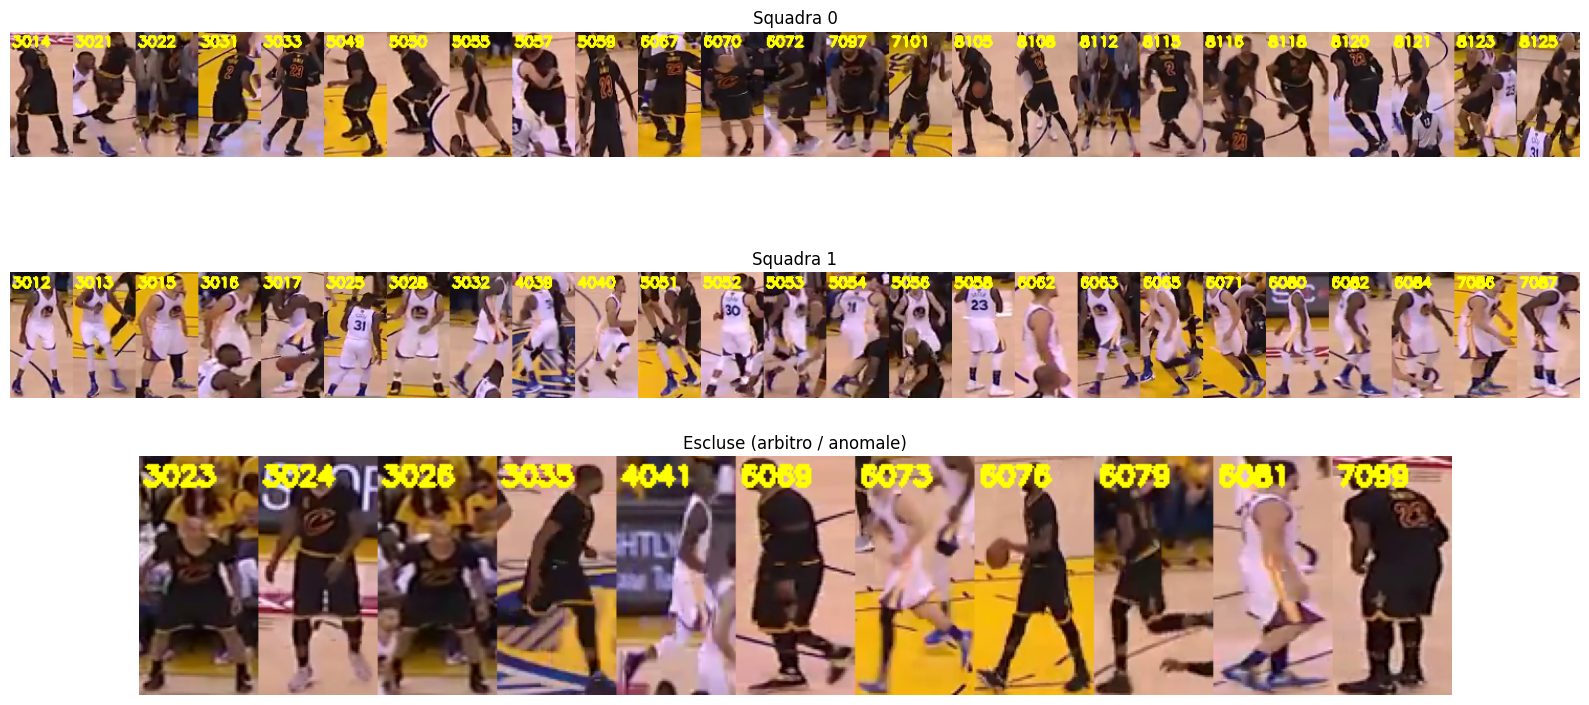

In [5]:
length = tracks.groupby('track_id').size(); drop = []
for fi, g in tracks.groupby('frame'):
    if len(g) < 2: continue
    M = iou_xyxy(g[['x1', 'y1', 'x2', 'y2']].values, g[['x1', 'y1', 'x2', 'y2']].values); np.fill_diagonal(M, 0)
    ids, idx = g.track_id.values, g.index.values
    for i, j in zip(*np.where(np.triu(M) > DUP_IOU)):
        drop.append(idx[i] if length[ids[i]] < length[ids[j]] else idx[j])
tracks = tracks.drop(index=sorted(set(drop))).reset_index(drop=True)
tracks['foot_x'] = (tracks.x1 + tracks.x2) / 2; tracks['foot_y'] = tracks.y2
tracks['foot_ok'] = tracks.y2 < H_IMG - 3
if SCOREBOARD_REL:
    sx1, sy1, sx2, sy2 = SCOREBOARD_REL[0] * W_IMG, SCOREBOARD_REL[1] * H_IMG, SCOREBOARD_REL[2] * W_IMG, SCOREBOARD_REL[3] * H_IMG
    tracks.loc[tracks.foot_x.between(sx1, sx2) & tracks.y2.between(sy1 - 6, sy2), 'foot_ok'] = False

# feature della maglia: un solo passaggio sul video, solo sui frame necessari
need = set(range(0, N, 3)); court_px = []
feat_rows = []
by_f = dict(tuple(tracks[tracks.frame % 3 == 0].groupby('frame')))
for fi, f in frames_iter(step=3, desc='colori maglia'):
    if fi % 30 == 0:
        court_px.append(cv2.cvtColor(np.ascontiguousarray(f[int(.6*H_IMG):int(.78*H_IMG), int(.2*W_IMG):int(.8*W_IMG)]), cv2.COLOR_BGR2LAB).reshape(-1, 3))
    g = by_f.get(fi)
    if g is None: continue
    bxs = g[['x1', 'y1', 'x2', 'y2']].values; Mo = iou_xyxy(bxs, bxs); np.fill_diagonal(Mo, 0)
    ov = Mo.max(1) if len(bxs) > 1 else np.zeros(len(bxs))
    for r, o in zip(g.itertuples(), ov):
        x1, y1, x2, y2 = max(0, int(r.x1)), max(0, int(r.y1)), min(W_IMG, int(r.x2)), min(H_IMG, int(r.y2))
        w, h = x2 - x1, y2 - y1
        if h < 30 or w < 8: continue
        crop = np.ascontiguousarray(f[y1 + int(.15*h):y1 + int(.5*h), x1 + int(.2*w):x2 - int(.2*w)])
        if crop.size: feat_rows.append((r.track_id, fi, cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).reshape(-1, 3).astype(np.float32), o > OCC_IOU))
COURT_LAB = np.median(np.concatenate(court_px).astype(np.float32), axis=0)
def hist_of(lab):
    lab = lab[np.linalg.norm(lab - COURT_LAB, axis=1) > 25]
    if len(lab) < 20: return None
    h = np.histogramdd(lab, bins=(4, 6, 6), range=((0, 256), (0, 256), (0, 256)))[0].ravel(); return h / h.sum()
F, K, R, O = [], [], [], []
for tid, fi, lab, occ in feat_rows:
    h = hist_of(lab)
    if h is not None: F.append(h); K.append(tid); R.append(fi); O.append(occ)
F, K, R, O = np.array(F), np.array(K), np.array(R), np.array(O, bool)
if len(K):                                                     # i campioni "sovrapposti" restano solo per le tracce che non ne hanno di puliti
    has_clean = pd.Series(~O).groupby(K).transform('any').values
    keep = ~O | ~has_clean; F, K, R = F[keep], K[keep], R[keep]
    print(f'campioni colore: {len(O)} | scartati perché sovrapposti: {int((~keep).sum())}')

class KMeans2:
    def __init__(self, n_init=20, iters=100, seed=0): self.n_init, self.iters, self.rng = n_init, iters, np.random.default_rng(seed)
    def fit(self, X):
        X = np.asarray(X, np.float64); best = None
        for _ in range(self.n_init):
            C = X[self.rng.choice(len(X), 2, replace=len(X) < 2)].copy()
            for _ in range(self.iters):
                lab = self._assign(X, C)
                newC = np.array([X[lab == k].mean(0) if (lab == k).any() else C[k] for k in range(2)])
                if np.allclose(newC, C): break
                C = newC
            inertia = ((X - C[self._assign(X, C)]) ** 2).sum()
            if best is None or inertia < best[0]: best = (inertia, C)
        self.cluster_centers_ = best[1]; return self
    @staticmethod
    def _assign(X, C): return np.argmin(((X[:, None, :] - C[None]) ** 2).sum(-1), axis=1)
    def predict(self, X): return self._assign(np.asarray(X, np.float64), self.cluster_centers_)

def fit_teams(F, K):
    med = {int(t): np.median(F[K == t], axis=0) for t in np.unique(K)}
    n = pd.Series(K).value_counts()
    fit_ids = [t for t in med if n[t] >= 5] or list(med)
    outliers = set()
    for _ in range(2):
        km = KMeans2().fit(np.array([med[t] for t in fit_ids if t not in outliers]))
        lum = [(c.reshape(4, 6, 6).sum((1, 2)) * np.array([32, 96, 160, 224])).sum() for c in km.cluster_centers_]
        if lum[0] > lum[1]: km.cluster_centers_ = km.cluster_centers_[::-1].copy()
        team = {t: int(km.predict(med[t][None])[0]) for t in med}
        d = pd.Series({t: np.linalg.norm(med[t] - km.cluster_centers_[team[t]]) for t in med})
        dl = d[[t for t in fit_ids if t not in outliers]]
        thr = dl.median() + OUTLIER_K * max((dl - dl.median()).abs().median() * 1.4826, 0.25 * dl.median(), 1e-6)
        outliers |= set(d.index[d > thr])
    for t in outliers: team[t] = -1
    return km, team

km, team_of = fit_teams(F, K)
n_split = 0; lab_s = km.predict(F); next_id = int(tracks.track_id.max()) + 1; remap = []
for tid in np.unique(K):
    if team_of[int(tid)] < 0: continue
    sel = np.argsort(R[K == tid]); f_t = R[K == tid][sel]; l_t = lab_s[K == tid][sel]
    other = l_t != team_of[int(tid)]; run_start, cnt, cuts_t = None, 0, []
    for k, o in enumerate(other):
        if o: run_start = k if cnt == 0 else run_start; cnt += 1
        else:
            if cnt >= SPLIT_MIN_SAMPLES: cuts_t.append((f_t[run_start], f_t[k]))
            cnt = 0
    if cnt >= SPLIT_MIN_SAMPLES: cuts_t.append((f_t[run_start], N))
    for a, b in cuts_t:
        m = (tracks.track_id == tid) & (tracks.frame >= a) & (tracks.frame < b)
        tracks.loc[m, 'track_id'] = next_id; remap.append((tid, a, b, next_id)); next_id += 1; n_split += 1
for tid, a, b, nid in remap:
    m = (K == tid) & (R >= a) & (R < b); K[m] = nid
if n_split: km, team_of = fit_teams(F, K)
ref_by = {f: g[['x1', 'y1', 'x2', 'y2']].values for f, g in det[(det['name'] == 'referee') & (det.conf >= 0.3)].groupby('frame')}
for tid, g in tracks[tracks.frame % 3 == 0].groupby('track_id'):
    hits = [f in ref_by and iou_xyxy(np.array([[x1, y1, x2, y2]]), ref_by[f]).max() > 0.5
            for f, x1, y1, x2, y2 in g[['frame', 'x1', 'y1', 'x2', 'y2']].itertuples(index=False)]
    if hits and np.mean(hits) >= 0.3: team_of[int(tid)] = -1
tracks['team'] = tracks.track_id.map(team_of).fillna(-1).astype(int)
print('tracce divise:', n_split, '| tracce per squadra:', pd.Series(team_of).value_counts().to_dict(),
      '| escluse:', len([t for t, k in team_of.items() if k < 0]))
TEAM_COLORS = {0: (255, 140, 30), 1: (40, 40, 230), -1: (160, 160, 160)}    # BGR: squadra 0 (scura) blu, 1 (chiara) rossa

# foglio di controllo: un ritaglio per traccia lunga
long_ids = tracks.groupby('track_id').size().loc[lambda s: s >= FPS].index
mid = {tid: int(g.frame.iloc[len(g) // 2]) for tid, g in tracks[tracks.track_id.isin(long_ids)].groupby('track_id')}
crops = {}
want = {f: [t for t, ff in mid.items() if ff == f] for f in set(mid.values())}
for fi, f in frames_iter(wanted=set(want), desc='foglio squadre'):
    for tid in want[fi]:
        r = tracks[(tracks.track_id == tid) & (tracks.frame == fi)].iloc[0]
        c = np.ascontiguousarray(f[max(0, int(r.y1)):min(H_IMG, int(r.y2)), max(0, int(r.x1)):min(W_IMG, int(r.x2))])
        if c.size and c.shape[0] > 1 and c.shape[1] > 1:
            c = cv2.resize(c, (60, 120)); cv2.putText(c, str(tid), (2, 14), cv2.FONT_HERSHEY_SIMPLEX, .45, (0, 255, 255), 2); crops[tid] = c
fig, axes = plt.subplots(3, 1, figsize=(16, 7.5))
for ax, team in zip(axes, [0, 1, -1]):
    cc = [crops[t] for t in sorted(crops) if team_of.get(t, -1) == team][:25]
    if cc: ax.imshow(cv2.cvtColor(np.hstack(cc), cv2.COLOR_BGR2RGB))
    ax.set_title(f'Squadra {team}' if team >= 0 else 'Escluse (arbitro / anomale)'); ax.axis('off')
fig.tight_layout(); fig.savefig(OUT / 'controllo_squadre.png', dpi=130); plt.show()

tracce che il detector chiama "referee" (colore = distanza / mediana della squadra):
 track_id  campioni_colore  colore decisione
     2009                3    1.50   arbitro
     2010                7    1.22 giocatore
     3024               27    0.61 giocatore
     3026               17    1.58   arbitro
tracce per squadra: {0: 59, 1: 56, -1: 12} | motivi esclusione: {'NOCOL': 10, 'REF': 2}


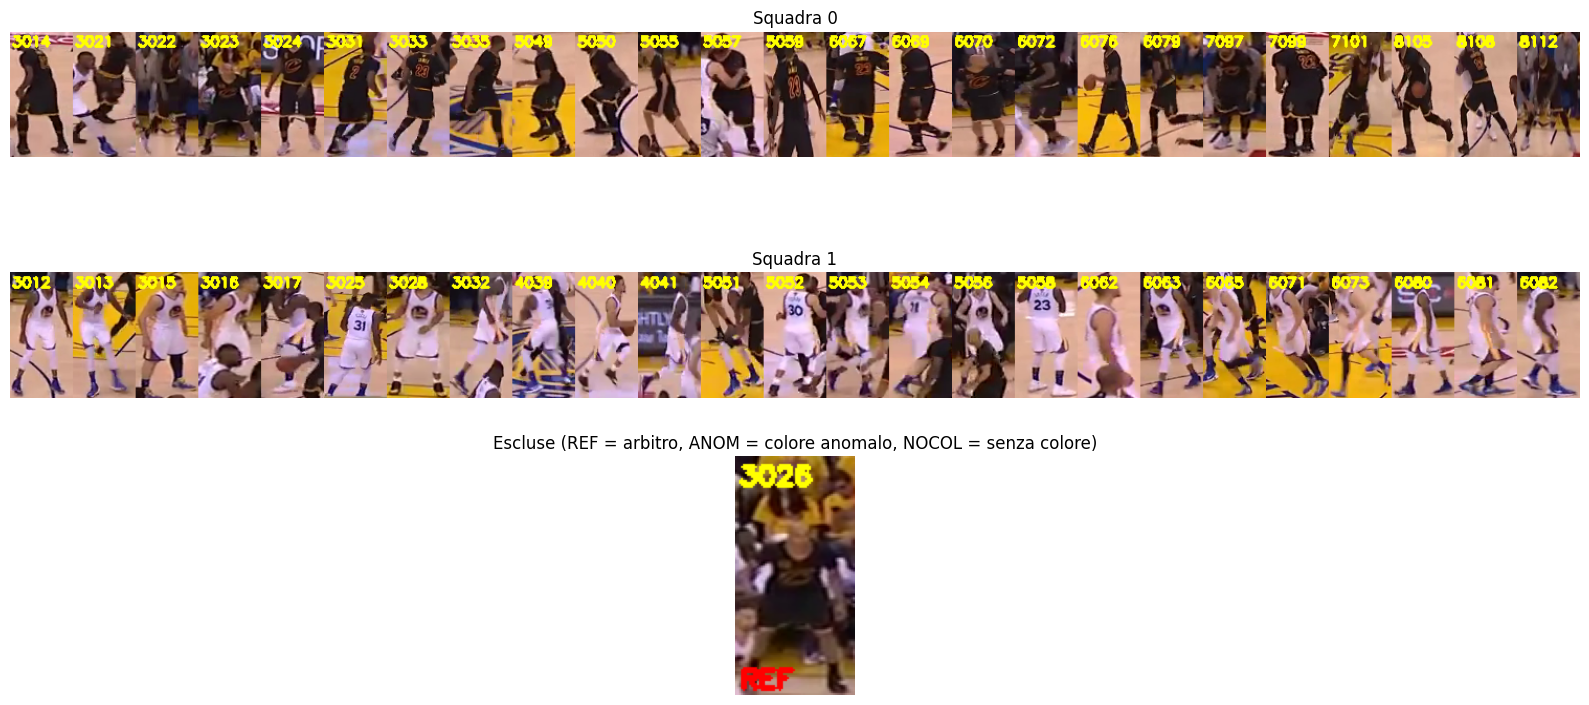

In [6]:
# 3b. ARBITRO E ANOMALE, VERSIONE CORRETTA
# arbitro = nei frame della traccia il detector è più sicuro di "referee" che di "player" (non basta che esista un box referee)
# anomala = solo tracce con abbastanza campioni di colore e molto lontane da entrambe le squadre; le tracce corte vanno alla squadra più vicina
REF_VOTE = 0.5          # quota minima di frame in cui "referee" batte "player"
OUTLIER_K2 = 5.0        # più alto = meno tracce scartate per colore
MIN_COL = 5             # campioni di colore minimi per poter scartare una traccia per colore
REF_KEEP = 1.25         # "arbitro" per il detector ma colore vicino a una squadra (distanza < 1,25 x la mediana della squadra) -> resta giocatore
                        # su az1: giocatori 1,16-1,21, arbitri 1,43-2,10, persona fuori campo 1,29
DROP_NOCOL = True       # tracce senza colore utile (frammenti corti/piccoli): eliminate invece di restare grigie

ref_all = {f: g[['x1', 'y1', 'x2', 'y2', 'conf']].values for f, g in det[det['name'] == 'referee'].groupby('frame')}
ply_all = {f: g[['x1', 'y1', 'x2', 'y2', 'conf']].values for f, g in det[det['name'].str.startswith('player')].groupby('frame')}
is_ref = {}
for tid, g in tracks[tracks.frame % 3 == 0].groupby('track_id'):
    votes = []
    for f, x1, y1, x2, y2 in g[['frame', 'x1', 'y1', 'x2', 'y2']].itertuples(index=False):
        rc = pc = 0.0
        for src, is_r in ((ref_all, True), (ply_all, False)):
            r = src.get(f)
            if r is None: continue
            iou = iou_xyxy(np.array([[x1, y1, x2, y2]]), r[:, :4])[0]
            c = float(r[iou > 0.5, 4].max()) if (iou > 0.5).any() else 0.0
            if is_r: rc = c
            else: pc = c
        votes.append(rc > pc)                                     # in questo frame il detector è più sicuro di "referee" che di "player"

    is_ref[int(tid)] = len(votes) >= 3 and np.mean(votes) >= REF_VOTE

med = {int(t): np.median(F[K == t], axis=0) for t in np.unique(K)}
n_col = pd.Series(K).value_counts()
near = {t: int(km.predict(m[None])[0]) for t, m in med.items()}
d = pd.Series({t: np.linalg.norm(m - km.cluster_centers_[near[t]]) for t, m in med.items()})
base = d[[t for t in med if not is_ref.get(t, False) and n_col[t] >= MIN_COL]]
thr = base.median() + OUTLIER_K2 * max((base - base.median()).abs().median() * 1.4826, 0.25 * base.median(), 1e-6)

team_med = {k: d[[t for t in med if near[t] == k and not is_ref.get(t, False) and n_col[t] >= MIN_COL]].median() for k in (0, 1)}
def typical(t): return t in med and n_col[t] >= MIN_COL and d[t] <= REF_KEEP * team_med[near[t]]
ref_tab = [(t, n_col.get(t, 0), round(d[t] / team_med[near[t]], 2) if t in med else None, 'giocatore' if typical(t) else 'arbitro')
           for t in sorted(k for k, v in is_ref.items() if v)]
print('tracce che il detector chiama "referee" (colore = distanza / mediana della squadra):'); print(pd.DataFrame(ref_tab, columns=['track_id', 'campioni_colore', 'colore', 'decisione']).to_string(index=False))
motivo = {}
for t in tracks.track_id.unique():
    t = int(t)
    if is_ref.get(t, False) and not typical(t): team_of[t] = -1; motivo[t] = 'REF'
    elif t not in med: team_of[t] = -1; motivo[t] = 'NOCOL'
    elif n_col[t] >= MIN_COL and d[t] > thr: team_of[t] = -1; motivo[t] = 'ANOM'
    else: team_of[t] = near[t]; motivo[t] = 'ok'
if DROP_NOCOL:
    tracks = tracks[~tracks.track_id.isin([t for t, m in motivo.items() if m == 'NOCOL'])].reset_index(drop=True)
tracks['team'] = tracks.track_id.map(team_of).fillna(-1).astype(int)
print('tracce per squadra:', pd.Series(team_of).value_counts().to_dict(), '| motivi esclusione:',
      pd.Series(motivo)[pd.Series(motivo) != 'ok'].value_counts().to_dict())

fig, axes = plt.subplots(3, 1, figsize=(16, 7.5))
for ax, team in zip(axes, [0, 1, -1]):
    ids = [t for t in sorted(crops) if team_of.get(t, -1) == team][:25]
    cc = []
    for t in ids:
        c = crops[t].copy()
        if team < 0: cv2.putText(c, motivo[t], (2, 116), cv2.FONT_HERSHEY_SIMPLEX, .45, (0, 0, 255), 2)
        cc.append(c)
    if cc: ax.imshow(cv2.cvtColor(np.hstack(cc), cv2.COLOR_BGR2RGB))
    ax.set_title(f'Squadra {team}' if team >= 0 else 'Escluse (REF = arbitro, ANOM = colore anomalo, NOCOL = senza colore)'); ax.axis('off')
fig.tight_layout(); fig.savefig(OUT / 'controllo_squadre.png', dpi=130); plt.show()

In [7]:
col = pd.DataFrame({int(t): m for t, m in med.items()}).T
col.insert(0, 'campioni', [int(n_col.get(t, 0)) for t in col.index])
col.insert(1, 'squadra', [team_of.get(t, -1) for t in col.index])
col.insert(2, 'referee_detector', [bool(is_ref.get(t, False)) for t in col.index])
col.to_csv(OUT / 'colori_tracce.csv', index_label='track_id')
print('salvati i colori di', len(col), 'tracce')

salvati i colori di 117 tracce


In [8]:
# 3c. RICUCITURA DELLE TRACCE: stesso giocatore, ID nuovo
# se una traccia finisce e poco dopo, nello stesso punto, ne nasce un'altra della stessa squadra, è lo stesso giocatore
STITCH_GAP_S = 1.0       # buco massimo tra la fine di una traccia e l'inizio dell'altra (secondi)
STITCH_DIST = 1.2        # distanza massima tra i due box, in altezze del giocatore (cresce un po' con il buco)
PASS_COEXIST_S = 0.5     # per un passaggio i due giocatori devono essere visti insieme almeno questo tempo

def stitch(tracks):
    ends = tracks.sort_values('frame').groupby('track_id').agg(f0=('frame', 'first'), f1=('frame', 'last'), team=('team', 'first'))
    first = tracks.sort_values('frame').groupby('track_id').first(); last = tracks.sort_values('frame').groupby('track_id').last()
    cand = []
    for a, ea in ends[ends.team >= 0].iterrows():
        la = last.loc[a]; ha = la.y2 - la.y1
        nxt = ends[(ends.team == ea.team) & (ends.f0 >= ea.f1 - 2) & (ends.f0 <= ea.f1 + STITCH_GAP_S * FPS) & (ends.index != a)]
        for b, eb in nxt.iterrows():
            if scene_of[int(eb.f0)] != scene_of[int(ea.f1)]: continue
            fb = first.loc[b]; hb = fb.y2 - fb.y1
            if not 0.67 <= hb / max(ha, 1) <= 1.5: continue
            gap = max(0, eb.f0 - ea.f1)
            d = np.hypot((la.x1 + la.x2 - fb.x1 - fb.x2) / 2, la.y2 - fb.y2) / max(ha, 1)
            if d <= STITCH_DIST * (1 + gap / FPS): cand.append((d, int(a), int(b)))
    succ, pred = {}, {}
    for d, a, b in sorted(cand):
        if a in succ or b in pred: continue
        succ[a], pred[b] = b, a
    root = {}
    for b in sorted(pred, key=lambda t: ends.f0[t]):
        r = pred[b]
        while r in pred: r = pred[r]
        root[b] = r
    tracks = tracks.copy(); tracks['track_id'] = tracks.track_id.replace(root)
    tracks = tracks.sort_values(['track_id', 'frame']).drop_duplicates(['track_id', 'frame']).reset_index(drop=True)
    return tracks, root

n_before = tracks.track_id.nunique()
tracks, root = stitch(tracks)
for b, r in root.items(): team_of[r] = team_of.get(r, team_of.get(b, -1))
print(f'tracce: {n_before} -> {tracks.track_id.nunique()} ({len(root)} cambi di ID ricuciti)')

tracce: 117 -> 95 (22 cambi di ID ricuciti)


## 4. Omografia (per scena) e posizioni sul campo

In [9]:
from sports import MeasurementUnit
from sports.basketball import CourtConfiguration, League, draw_court
LEAGUE = League.FIBA if LEAGUE_NAME == 'fiba' else League.NBA
court = CourtConfiguration(league=LEAGUE, measurement_unit=MeasurementUnit.FEET)
V = np.asarray(court.vertices, dtype=np.float32)
L_FT, W_FT = float(court.court_length), float(court.court_width)

hfile = OUT / f'homographies_{tag}_{LEAGUE.value}.json'
if hfile.is_file():
    hs = {int(k): np.asarray(v) for k, v in json.loads(hfile.read_text()).items()}
else:
    from inference import get_model
    try:
        from google.colab import userdata; API_KEY = userdata.get('ROBOFLOW_API_KEY')
    except Exception:
        API_KEY = os.environ.get('ROBOFLOW_API_KEY') or __import__('getpass').getpass('API key Roboflow: ')
    court_model = get_model(model_id=COURT_MODEL_ID, api_key=API_KEY)
    hs = {}
    for fi, f in frames_iter(step=HOMO_EVERY, desc='omografia'):
        if excluded[fi]: continue
        res = court_model.infer(f, confidence=0.3)[0]
        if not res.predictions: continue
        pr = max(res.predictions, key=lambda p: p.confidence)
        pts = [p for p in pr.keypoints if p.confidence >= 0.5 and 0 <= p.class_id < len(V)]
        if len(pts) >= 6:
            fwd, mask = cv2.findHomography(V[[p.class_id for p in pts]], np.float32([[p.x, p.y] for p in pts]), cv2.RANSAC, 8.0)
            if fwd is not None and mask is not None and mask.sum() >= 6:
                try: hs[fi] = np.linalg.inv(fwd)
                except np.linalg.LinAlgError: pass
    hfile.write_text(json.dumps({str(k): v.tolist() for k, v in hs.items()}))
# omografia del frame calcolato più vicino, ma solo nella stessa scena (mai attraverso un taglio)
Hs = [None] * N
for sc in np.unique(scene_of):
    fr_sc = np.where(scene_of == sc)[0]; ks = np.array([k for k in hs if scene_of[k] == sc])
    if len(ks) == 0: continue
    for fi in fr_sc: Hs[fi] = hs[int(ks[np.abs(ks - fi).argmin()])]
print(f'omografie valide: {len(hs)} | frame senza omografia: {sum(h is None for h in Hs)} su {N}')

def to_court(x, y, fi):
    H = Hs[int(fi)]
    if H is None: return (np.nan, np.nan)
    p = cv2.perspectiveTransform(np.float32([[[x, y]]]), H)[0, 0]; return float(p[0]), float(p[1])
xy = [to_court(r.foot_x, r.foot_y, r.frame) if r.foot_ok else (np.nan, np.nan) for r in tracks.itertuples()]
tracks[['x_ft', 'y_ft']] = np.array(xy)
tracks[['x_raw', 'y_raw']] = tracks[['x_ft', 'y_ft']].values             # posizione non tagliata ai bordi: serve per riconoscere chi sta fuori dal campo
tracks.loc[~(tracks.x_ft.between(-3, L_FT + 3) & tracks.y_ft.between(-3, W_FT + 3)), ['x_ft', 'y_ft']] = np.nan
W_SM = max(3, int(round(FPS / 2)) | 1)
tracks = tracks.sort_values(['track_id', 'frame']).reset_index(drop=True)
tracks[['xs_ft', 'ys_ft']] = tracks.groupby('track_id')[['x_ft', 'y_ft']].transform(
    lambda s: s.rolling(W_SM, center=True, min_periods=1).median().rolling(5, center=True, min_periods=1).mean())
v = tracks[tracks.x_raw.notna()]
outside = ~(v.x_raw.between(-OUT_MARGIN_FT, L_FT + OUT_MARGIN_FT) & v.y_raw.between(-OUT_MARGIN_FT, W_FT + OUT_MARGIN_FT))
frac_out = outside.groupby(v.track_id).mean(); n_pos = v.groupby('track_id').size()
fuori = [int(t) for t in frac_out.index if frac_out[t] >= OUT_FRAC and n_pos[t] >= 10]
tracks = tracks[~tracks.track_id.isin(fuori)].reset_index(drop=True)
for t in fuori: team_of[t] = -1
print('persone fuori dal campo (panchina, staff, tifosi) eliminate:', len(fuori), fuori[:20])
tracks.to_csv(OUT / 'tracks_court.csv', index=False)
print('posizioni sul campo valide:', int(tracks.xs_ft.notna().sum()), 'su', len(tracks))

omografie valide: 499 | frame senza omografia: 0 su 1800
persone fuori dal campo (panchina, staff, tifosi) eliminate: 0 []
posizioni sul campo valide: 9675 su 10136


## 4b. Punteggio dal tabellone (per distinguere tiri segnati e sbagliati)

Il detector riconosce male "ball-in-basket" (in az1 0,69 di confidenza su tiri sbagliati, in az4 quasi mai). Si usa invece il **tabellone**: quando le cifre del punteggio di una squadra cambiano e restano cambiate per 1,5 s, quella squadra ha segnato. Non serve leggere i numeri (l'OCR confonde 3, 8 e 9): basta accorgersi che l'immagine delle cifre è cambiata. Funziona solo quando il tabellone è visibile (non nei replay e nei primi piani senza grafica).

In [10]:
def rel_crop(f, box):
    x1, y1, x2, y2 = box; return f[int(y1 * H_IMG):int(y2 * H_IMG), int(x1 * W_IMG):int(x2 * W_IMG)]
def digits(c):
    g = cv2.resize(cv2.cvtColor(c, cv2.COLOR_BGR2GRAY), (64, 40))
    _, b = cv2.threshold(g, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return (1 - b if b.mean() > .5 else b).astype(np.float32)
def sdiff(a, b, r=4):
    # differenza tra due immagini di cifre, tollerando piccoli spostamenti del tabellone (qualche pixel)
    return min(np.abs(np.roll(np.roll(a, dy, 0), dx, 1) - b)[r:-r, r:-r].mean() for dy in range(-r, r + 1) for dx in range(-r, r + 1))
SB_STEP = 3; sb_f, sb_logo, sb_dig = [], [], {k: [] for k in SCORE_BOXES}
for fi, f in frames_iter(step=SB_STEP, desc='tabellone'):
    sb_f.append(fi); sb_logo.append(cv2.resize(cv2.cvtColor(rel_crop(f, SCORE_LOGO), cv2.COLOR_BGR2GRAY), (64, 24)).astype(np.float32) / 255)
    for k, b in SCORE_BOXES.items(): sb_dig[k].append(digits(rel_crop(f, b)))
tmpl = np.median(np.stack(sb_logo), 0); sb_vis = np.array([np.abs(l - tmpl).mean() < 0.2 for l in sb_logo])
score_changes = []                                             # (frame, lato)
H_SB = int(round(SCORE_HOLD_S * FPS / SB_STEP))
for k in SCORE_BOXES:
    # v3: il punteggio di riferimento è la MAGGIORANZA dei pixel su 1,5 s stabili (non un singolo frame):
    # niente falsi canestri dall'animazione d'ingresso del tabellone o dal rumore di compressione
    seq = [(fi, m) for fi, m, vis in zip(sb_f, sb_dig[k], sb_vis) if vis and not excluded[fi]]   # frame senza tabellone: saltati
    ref, i = None, 0
    while i < len(seq):
        win = [m for _, m in seq[i:i + H_SB]]
        if ref is None:                                            # primo punteggio stabile = riferimento
            if len(win) < H_SB: break
            maj = (np.mean(win, 0) > 0.5).astype(np.float32)
            if np.mean([sdiff(m, maj) <= SCORE_THR for m in win]) >= SCORE_FRAC: ref = maj; i += H_SB
            else: i += 1
            continue
        if sdiff(seq[i][1], ref) <= SCORE_THR: i += 1; continue
        start = seq[i][0]
        if len(win) < H_SB:                                        # canestro proprio alla fine della clip
            if len(win) * SB_STEP >= 0.3 * FPS and np.mean([sdiff(m, ref) > SCORE_THR for m in win]) >= SCORE_FRAC: score_changes.append((start, k))
            break
        maj = (np.mean(win, 0) > 0.5).astype(np.float32)
        if (np.mean([sdiff(m, ref) > SCORE_THR for m in win]) >= SCORE_FRAC and np.mean([sdiff(m, maj) <= SCORE_THR for m in win]) >= SCORE_FRAC
                and sdiff(maj, ref) > SCORE_THR):                  # nuovo punteggio diverso dal vecchio e stabile per 1,5 s
            if not (score_changes and score_changes[-1][1] == k and start - score_changes[-1][0] < 4 * FPS):   # animazione in due tempi = un solo canestro
                score_changes.append((start, k))
            ref = maj; i += H_SB
        else: i += 1
play = ~excluded[np.array(sb_f)]                                 # visibilità calcolata solo sui tratti di gioco (non su pause e replay esclusi)
vis_pct = float(sb_vis[play].mean()) if play.any() else 0.0
score_changes.sort(); SCORE_OK = vis_pct >= 0.5
print(f'tabellone visibile nel {100 * vis_pct:.0f}% dei frame di gioco | canestri letti dal tabellone:',
      [(round(f / FPS + START_S, 1), k) for f, k in score_changes], '' if SCORE_OK else '(tabellone poco visibile: si usa ball-in-basket)')

tabellone:   0%|          | 0/1800 [00:00<?, ?it/s]

tabellone visibile nel 100% dei frame di gioco | canestri letti dal tabellone: [(29.7, 'L'), (43.0, 'R')] 


## 5. Palla: tracker di Kalman

Per ogni frame si considerano tutti i candidati `ball` (≥ `BALL_MIN_CONF`). Se la palla è agganciata, si accetta solo il candidato più vicino alla posizione **prevista** dal moto (entro un raggio che cresce con i frame di assenza); se nessun candidato è plausibile la palla resta "prevista" per al massimo `BALL_MAX_MISS` frame, poi è persa. Si riaggancia solo con una detection sicura (≥ `BALL_INIT_CONF`). Il tracker riparte a ogni taglio di scena.

In [11]:
def new_kf(x, y):
    kf = cv2.KalmanFilter(4, 2)
    kf.transitionMatrix = np.array([[1, 0, 1, 0], [0, 1, 0, 1], [0, 0, 1, 0], [0, 0, 0, 1]], np.float32)
    kf.measurementMatrix = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], np.float32)
    kf.processNoiseCov = np.diag([1, 1, 8, 8]).astype(np.float32)
    kf.measurementNoiseCov = np.eye(2, dtype=np.float32) * 4
    kf.statePost = np.array([[x], [y], [0], [0]], np.float32); kf.errorCovPost = np.eye(4, dtype=np.float32) * 50
    return kf

bc = det[(det['name'] == 'ball') & (det.conf >= BALL_MIN_CONF)].copy()
bc['cx'] = (bc.x1 + bc.x2) / 2; bc['cy'] = (bc.y1 + bc.y2) / 2
cand_by = {f: g[['cx', 'cy', 'conf']].values for f, g in bc.groupby('frame')}
acc = np.full((N, 2), np.nan); kf, miss, reinit = None, 0, 0
for fi in range(N):
    if excluded[fi] or (fi > 0 and scene_of[fi] != scene_of[fi - 1]): kf, miss = None, 0
    if excluded[fi]: continue
    C = cand_by.get(fi, np.zeros((0, 3)))
    if kf is not None:
        pred = kf.predict()[:2].ravel()
        if len(C):
            d = np.hypot(C[:, 0] - pred[0], C[:, 1] - pred[1]); j = int(d.argmin())
            if d[j] <= BALL_GATE * W_IMG * (1 + miss):
                kf.correct(C[j, :2].astype(np.float32).reshape(2, 1)); acc[fi] = C[j, :2]; miss = 0; continue
        miss += 1
        if miss > BALL_MAX_MISS: kf, miss = None, 0
    if kf is None and len(C) and C[:, 2].max() >= BALL_INIT_CONF:
        j = int(C[:, 2].argmax()); kf = new_kf(*C[j, :2]); acc[fi] = C[j, :2]; reinit += 1
ball = pd.DataFrame(acc, columns=['bx', 'by'])
filled = ball.copy()
for sc in np.unique(scene_of):                            # riempimento dei buchi brevi, solo dentro la scena
    m = scene_of == sc
    filled.loc[m] = ball.loc[m].interpolate(limit=BALL_FILL, limit_area='inside')
ball = filled
valid_frames = (~excluded).sum()
print(f'palla: candidati in {len(cand_by) / valid_frames:.0%} dei frame | accettata in {np.isfinite(acc[:, 0]).sum() / valid_frames:.0%} '
      f'| dopo riempimento {ball.bx.notna().sum() / valid_frames:.0%} | riagganci: {reinit}')

palla: candidati in 80% dei frame | accettata in 65% | dopo riempimento 81% | riagganci: 18


## 6. Possesso ed eventi automatici (regole del notebook 14 v2, mai attraverso un taglio di scena)

In [12]:
by_frame = dict(tuple(tracks[tracks.team >= 0].groupby('frame')))
raw = np.full(N, -1); last_team, last_fi = -1, -10**9
for fi in range(N):
    if fi > 0 and scene_of[fi] != scene_of[fi - 1]: last_team = -1
    g = by_frame.get(fi)
    if g is None or excluded[fi]: continue
    p = g[(g.cls == 'player-in-possession') & (g.cls_conf >= POSS_CONF)]
    bx, by = ball.bx[fi], ball.by[fi]
    if len(p):
        if len(p) > 1 and not np.isnan(bx):
            p = p.assign(d=np.hypot((p.x1 + p.x2) / 2 - bx, (p.y1 + p.y2) / 2 - by)).sort_values('d')
        raw[fi] = int(p.track_id.iloc[0]); last_team, last_fi = int(p.team.iloc[0]), fi; continue
    if np.isnan(bx): continue
    h = (g.y2 - g.y1).values
    dx = np.maximum.reduce([g.x1.values - bx, np.zeros(len(g)), bx - g.x2.values])
    dy = np.maximum.reduce([g.y1.values - by, np.zeros(len(g)), by - g.y2.values])
    d = np.hypot(dx, dy) / np.maximum(h, 1); k = int(d.argmin())
    if d[k] > POSS_RADIUS: continue
    near = np.where((d <= d[k] + POSS_TIE) & (g.team.values == last_team))[0]
    if len(near) and g.team.values[k] != last_team and fi - last_fi <= 0.3 * FPS: k = int(near[d[near].argmin()])   # contesa con un avversario subito dopo un possesso: vince il compagno
    raw[fi] = int(g.track_id.values[k]); last_team, last_fi = int(g.team.values[k]), fi
poss = np.full(N, -1); cur, cand, cnt, cand_start, lost = -1, -1, 0, 0, 0
for fi in range(N):
    if fi > 0 and scene_of[fi] != scene_of[fi - 1]: cur, cand, cnt, lost = -1, -1, 0, 0
    r = raw[fi]
    if r != cur:                                            # il portatore non è più confermato (palla persa o vicina a un altro)
        lost += 1
        if lost > POSS_LOST: cur = -1
    if r != -1:
        if r == cur: cand, cnt, lost = -1, 0, 0
        else:
            if r == cand: cnt += 1
            else: cand, cnt, cand_start = r, 1, fi
            if cnt >= POSS_MIN: cur = cand; poss[cand_start:fi] = cur; cand, cnt = -1, 0
    poss[fi] = cur
segs, s = [], None
for fi in range(N + 1):
    v = poss[fi] if fi < N else -2
    if s is not None and (v != s[0] or (fi < N and scene_of[fi] != scene_of[s[1]])):
        segs.append({'track_id': s[0], 'start': s[1], 'end': fi - 1}); s = None
    if s is None and fi < N and v >= 0: s = (v, fi)
sg = pd.DataFrame(segs, columns=['track_id', 'start', 'end'])
sg['team'] = sg.track_id.map(team_of).fillna(-1).astype(int); sg = sg[sg.team >= 0]
n_raw = len(sg); changed = True
while changed and len(sg):
    changed = False
    short = sg[(sg.end - sg.start + 1) / FPS < MIN_SEG_S]
    if len(short): sg = sg.drop(index=short.index); changed = True
    sg = sg.sort_values('start').reset_index(drop=True); merged = []
    for r in sg.to_dict('records'):
        if merged and merged[-1]['track_id'] == r['track_id'] and (r['start'] - merged[-1]['end']) / FPS <= PASS_MAX_GAP_S:
            merged[-1]['end'] = r['end']; changed = True
        else: merged.append(dict(r))
    sg = pd.DataFrame(merged, columns=['track_id', 'start', 'end', 'team'])
if len(sg):
    sg['team_run'] = ((sg.team != sg.team.shift()) | (scene_of[sg.start.values] != scene_of[sg.start.shift().fillna(0).astype(int).values])).cumsum()
    run_dur = (sg.groupby('team_run').end.max() - sg.groupby('team_run').start.min() + 1) / FPS
    sg['team_run_s'] = sg.team_run.map(run_dur)
    # v3: possesso di squadra anche attraverso i tagli di scena (stessa squadra, buco <= STEAL_GAP_S): serve alle palle rubate
    sg['team_poss'] = ((sg.team != sg.team.shift()) | ((sg.start - sg.end.shift().fillna(-1e9)) / FPS > STEAL_GAP_S)).cumsum()
    poss_dur = (sg.groupby('team_poss').end.max() - sg.groupby('team_poss').start.min() + 1) / FPS
    sg['team_poss_s'] = sg.team_poss.map(poss_dur)
segs = sg
poss = np.full(N, -1)
for r in segs.itertuples(): poss[int(r.start):int(r.end) + 1] = int(r.track_id)
print(f'possesso: {n_raw} segmenti grezzi -> {len(segs)} dopo la pulizia')

def pos_at(tid, fi, win=60):
    g = tracks[(tracks.track_id == tid) & tracks.xs_ft.notna() & tracks.frame.between(fi - win, fi + win)]
    if not len(g): return (np.nan, np.nan)
    r = g.iloc[(g.frame - fi).abs().argmin()]; return float(r.xs_ft), float(r.ys_ft)
R3 = court.three_point_arc_radius; STRAIGHT = court.straight_section_three_point_line
CORNER = W_FT / 2 - court.sideline_to_three_point_line
BASKETS = [(court.baseline_to_rim_center, W_FT / 2), (L_FT - court.baseline_to_rim_center, W_FT / 2)]
def shot_value(x, y):
    if np.isnan(x): return np.nan, np.nan
    bx, byy = min(BASKETS, key=lambda b: abs(b[0] - x)); d = float(np.hypot(x - bx, y - byy))
    from_baseline = x if bx < L_FT / 2 else L_FT - x
    three = abs(y - byy) >= CORNER if from_baseline <= STRAIGHT else d >= R3
    return (3 if three else 2), d * FT_TO_M

sh = tracks[tracks.cls.isin(['player-jump-shot', 'player-layup-dunk']) & (tracks.cls_conf >= 0.3) & (tracks.team >= 0)]
cand_s = []
for tid, g in sh.groupby('track_id'):
    f = g.frame.values
    for r in np.split(f, np.where(np.diff(f) > 3)[0] + 1):
        if len(r) >= SHOT_MIN_FRAMES: cand_s.append((int(r[0]), int(tid), len(r), None))
# tiri dalla traiettoria della palla (oltre alle classi "tiro" del detector)
rim_by = {f: g[['x1', 'y1', 'x2', 'y2']].values for f, g in det[(det['name'] == 'rim') & (det.conf >= RIM_CONF)].groupby('frame')}
rim_frames = np.array(sorted(rim_by)); near_rim = np.zeros(N, bool)
for fi in range(N):
    if excluded[fi] or np.isnan(ball.bx[fi]) or not len(rim_frames): continue
    k = int(rim_frames[np.abs(rim_frames - fi).argmin()])
    if abs(k - fi) > 5 or scene_of[k] != scene_of[fi]: continue
    for x1, y1, x2, y2 in rim_by[k]:
        w = x2 - x1; h = max(y2 - y1, 0.3 * w)
        if x1 - 0.5 * w <= ball.bx[fi] <= x2 + 0.5 * w and y1 - 1.5 * h <= ball.by[fi] <= y2 + 0.3 * h:
            near_rim[fi] = True; break
def release_frame(c, max_back_s=2.5):
    # rilascio del tiro dalla traiettoria: dal ferro si torna indietro fino al punto più alto del volo,
    # poi si continua finché la palla è di nuovo dentro il box di un giocatore (le mani del tiratore)
    fs = [k for k in range(c, max(-1, c - int(max_back_s * FPS)), -1) if not np.isnan(acc[k, 0]) and scene_of[k] == scene_of[c]]
    if len(fs) < 3: return None
    apex = int(np.argmin([acc[k, 1] for k in fs]))
    for k in fs[apex:]:
        g = by_frame.get(k)
        if g is None: continue
        bx, by = acc[k]
        if ((g.x1 <= bx) & (bx <= g.x2) & (g.y1 <= by) & (by <= g.y2)).any(): return k
    return None
idx = np.where(near_rim)[0]; n_rim = 0
for run in (np.split(idx, np.where(np.diff(idx) > 5)[0] + 1) if len(idx) else []):
    if len(run) < RIM_MIN_FRAMES: continue
    c = int(run[0])
    prev = segs[(segs.start <= c + 0.3 * FPS) & (segs.end >= c - SHOT_LOOKBACK_S * FPS)]   # anche subito dopo un cambio di telecamera
    if not len(prev): continue
    r = prev.sort_values('start').iloc[-1]
    before = prev[(prev.end < c - 3) & (prev.start.apply(lambda f: scene_of[int(f)] == scene_of[c]))]
    if len(before) and r.start > c - 3: r = before.sort_values('end').iloc[-1]   # chi riceve la palla sotto canestro mentre arriva non è il tiratore
    f0w = max(0, min(c, int(r.end)) - int(1.5 * FPS))
    done = set(segs.track_id[(segs.end < r.start) & (segs.end >= f0w)].astype(int)) - {int(r.track_id)}   # chi ha già passato la palla non è il tiratore
    w = [int(raw[k]) for k in range(f0w, min(c, int(r.end)) + 1) if raw[k] >= 0 and scene_of[k] == scene_of[int(r.start)]
         and team_of.get(int(raw[k]), -1) == r.team and int(raw[k]) not in done]
    shooter = max(set(w), key=w.count) if w else int(r.track_id)      # tiratore = chi ha avuto più a lungo la palla nell'ultimo 1,5 s (stessa inquadratura)
    f_shot = max(int(r.start), min(int(r.end), c))
    rel = release_frame(c)
    if rel is not None and rel < f_shot:                           # il rilascio dalla traiettoria vince: tiratore = chi aveva la palla prima del rilascio
        w = [int(raw[k]) for k in range(max(0, rel - int(1.5 * FPS)), rel + 1) if raw[k] >= 0 and scene_of[k] == scene_of[rel]]
        if w: shooter, f_shot = max(set(w), key=w.count), rel
    cand_s.append((f_shot, shooter, 100, c)); n_rim += 1
n_cls = sum(1 for c in cand_s if c[2] < 100)
cand_s = [c for c in cand_s if c[2] >= 100 or near_rim[c[0]:c[0] + int(SHOT_WINDOW_S * FPS)].any()]   # un tiro esiste solo se la palla arriva al ferro
print('tiri riconosciuti dalla traiettoria verso il ferro:', n_rim, '| candidati dalla posa scartati perché la palla non arriva al ferro:', n_cls - sum(1 for c in cand_s if c[2] < 100))

def ball_free(f0, f1):
    # frame in cui la palla (vista davvero, non riempita) è fuori da tutti i giocatori
    n = 0
    for fi in range(max(0, f0 - 2), min(N, f1 + 3)):
        bx, by = acc[fi]
        if np.isnan(bx): continue
        g = by_frame.get(fi)
        if g is None: n += 1; continue
        mw = 0.1 * (g.x2 - g.x1)
        n += not ((g.x1 - mw <= bx) & (bx <= g.x2 + mw) & (g.y1 <= by) & (by <= g.y2)).any()
    return n

def exchange_ok(a, b):
    # passaggio / recupero plausibile: chi riceve era già visibile prima, e la palla non è sparita troppo a lungo nel mezzo
    born = tracks.frame[tracks.track_id == b.track_id].min()
    if born > b.start - PASS_SEEN_BEFORE_S * FPS: return False
    seen = np.isfinite(acc[int(a.end):int(b.start) + 1, 0])
    blind = max((len(r) for r in ''.join('1' if not v else '0' for v in seen).split('0')), default=0)
    return blind <= PASS_MAX_BLIND_S * FPS

shots = []
for f0, tid, n, c_rim in sorted(cand_s, key=lambda t: t[0]):
    if shots and f0 - shots[-1]['frame'] < 1.5 * FPS:
        if n > shots[-1]['_n']: shots[-1].update(frame=f0, track_id=tid, _n=n, c=c_rim)
        continue
    shots.append({'frame': f0, 'track_id': tid, '_n': n, 'c': c_rim})
def last_touch(tid, c):
    # ultimo frame prima dell'arrivo al ferro in cui la palla è nelle mani del tiratore = RILASCIO
    for k in range(c, max(-1, c - int(2.5 * FPS)), -1):
        if raw[k] == tid and scene_of[k] == scene_of[c]: return k
    return None
def through_rim(f0):
    # la palla, entro SHOT_WINDOW_S, viene vista sotto il ferro e dentro la sua larghezza (passa nella retina)
    for fi in range(f0, min(N, f0 + int(SHOT_WINDOW_S * FPS))):
        bx, by = acc[fi]
        if np.isnan(bx) or not len(rim_frames): continue
        k = int(rim_frames[np.abs(rim_frames - fi).argmin()])
        if abs(k - fi) > 5: continue
        for x1, y1, x2, y2 in rim_by[k]:
            w = x2 - x1
            if x1 + 0.1 * w <= bx <= x2 - 0.1 * w and y2 <= by <= y2 + 1.2 * w: return True
    return False
def shot_pos(tid, f):
    # posizione del tiro allo STACCO: nel salto il box si alza e la proiezione sul campo si sposta verso il canestro,
    # quindi si usa la mediana delle posizioni (non smussate) tra 0,7 e 0,25 s prima del rilascio, quando i piedi sono a terra
    g = tracks[(tracks.track_id == tid) & tracks.frame.between(f - int(0.7 * FPS), f - int(0.25 * FPS)) & tracks.x_ft.notna()]
    return (float(g.x_ft.median()), float(g.y_ft.median())) if len(g) >= 3 else pos_at(tid, f)
made_f = np.sort(det[(det['name'] == 'ball-in-basket') & (det.conf >= MADE_CONF)].frame.unique())
def ball_near(tid, f, before_s=0.7, after_s=0.3):
    # la palla (vista davvero) è nelle mani o sopra la testa del giocatore attorno al frame f
    g = tracks[(tracks.track_id == tid) & tracks.frame.between(f - int(before_s * FPS), f + int(after_s * FPS))]
    for r in g.itertuples():
        bx, by = acc[int(r.frame)]
        if np.isnan(bx): continue
        w, h = r.x2 - r.x1, r.y2 - r.y1
        if r.x1 - 0.5 * w <= bx <= r.x2 + 0.5 * w and r.y1 - 0.5 * h <= by <= r.y2: return True
    return False
events = []
for s in shots:
    s['team'] = team_of.get(s['track_id'], -1)
    if s['c'] is None and s['_n'] < 100 and not ball_near(s['track_id'], s['frame']):
        # v3: tiro visto solo dalla posa ("player-jump-shot") ma palla mai vista vicino a quel giocatore: il tiratore vero non è rilevato.
        # Meglio "tiratore non rilevato" che il compagno (o l'avversario) più vicino: squadra = chi aveva l'ultimo possesso prima del tiro
        pv = segs[segs.end <= s['frame']]
        if len(pv): s['team'] = int(pv.team.iloc[-1])
        s['track_id'] = -1
    w = made_f[(made_f >= s['frame']) & (made_f <= s['frame'] + SHOT_WINDOW_S * FPS) & (scene_of[made_f] == scene_of[s['frame']])]
    made = len(w) >= MADE_MIN_FRAMES
    if made and MADE_THROUGH: made = through_rim(s['frame'])
    if SCORE_OK:                                                  # il tabellone decide se è canestro e DI QUALE SQUADRA
        sides = [k for f, k in score_changes if s['frame'] <= f <= s['frame'] + MADE_WINDOW_S * FPS]
        made = bool(sides)
        if made:
            t_made = next((t for t, k in SCORE_SIDE.items() if k == sides[0]), -1)
            if s['team'] != t_made:                                # tiratore della squadra sbagliata (es. difensore vicino alla palla): si sceglie nella squadra che ha segnato
                f0 = s['frame']; w = [int(raw[k]) for k in range(max(0, f0 - int(1.5 * FPS)), f0 + 1) if raw[k] >= 0 and team_of.get(int(raw[k]), -1) == t_made]
                if not w and f0 in by_frame and not np.isnan(acc[f0, 0]):
                    g = by_frame[f0]; g = g[g.team == t_made]
                    if len(g): w = [int(g.iloc[np.hypot((g.x1 + g.x2) / 2 - acc[f0, 0], (g.y1 + g.y2) / 2 - acc[f0, 1]).argmin()].track_id)]
                if w: s['track_id'] = max(set(w), key=w.count)
                s['team'] = t_made
    if s['c'] is not None:                                        # il tiro avviene quando la palla lascia la mano, non quando arriva al ferro
        lt = last_touch(s['track_id'], s['c'])
        if lt is not None: s['frame'] = lt
        born = tracks.frame[tracks.track_id == s['track_id']].min()   # tiratore "nato" con un cambio di telecamera proprio durante il tiro:
        cut = max((c0 for c0 in cuts if born - 3 <= c0 <= s['frame']), default=None)   # il rilascio è nell'inquadratura precedente
        if cut is not None and s['frame'] - born < 0.5 * FPS:
            pv = segs[(segs.end >= cut - 6) & (segs.end < cut) & (segs.team == team_of.get(s['track_id'], -1))]
            if len(pv): s['track_id'], s['frame'] = int(pv.track_id.iloc[-1]), int(pv.end.iloc[-1])
    s['made'] = made
    if s['track_id'] >= 0: s['team'] = team_of.get(s['track_id'], s['team'])
    x, y = shot_pos(s['track_id'], s['frame']) if s['track_id'] >= 0 else (np.nan, np.nan); val, dist = shot_value(x, y)
    events.append({'tipo': 'tiro_segnato' if made else 'tiro_sbagliato', 'frame': s['frame'], 'da': s['track_id'] if s['track_id'] >= 0 else np.nan, 'a': np.nan,
                   'team': s['team'], 'x_ft': x, 'y_ft': y, 'x2_ft': np.nan, 'y2_ft': np.nan,
                   'dettaglio': f'da {val} punti, {dist:.1f} m' if not np.isnan(dist) else ('tiratore non rilevato' if s['track_id'] < 0 else '')})
for f, k in (score_changes if SCORE_OK else []):              # canestro letto dal tabellone ma nessun tiro trovato (palla persa in volo): il tiro c'è comunque
    if excluded[min(f, N - 1)] or any(s['made'] and s['frame'] <= f <= s['frame'] + MADE_WINDOW_S * FPS for s in shots): continue
    t_made = next((t for t, kk in SCORE_SIDE.items() if kk == k), -1)
    pv = segs[(segs.end <= f - 0.5 * FPS) & (segs.end >= f - MADE_WINDOW_S * FPS)].sort_values('end')   # possesso confermato finito prima del volo (almeno 0,5 s)
    if not len(pv): continue
    last = pv.iloc[-1]; same = pv[pv.team == t_made]
    sh_seg = same.iloc[-1] if len(same) else last                  # tiratore = ultimo giocatore DELLA SQUADRA CHE HA SEGNATO visto con la palla
    tid, fr = int(sh_seg.track_id), int(last.end)                  # tempo = ultimo istante in cui la palla era in mano a qualcuno, prima del volo
    x, y = shot_pos(tid, int(sh_seg.end)); val, dist = shot_value(x, y)   # posizione = dove il tiratore è stato visto per l'ultima volta
    shots.append({'frame': fr, 'track_id': tid, '_n': 0, 'c': None, 'made': True, 'f_score': int(f), 'team': t_made})
    events.append({'tipo': 'tiro_segnato', 'frame': fr, 'da': tid, 'a': np.nan, 'team': t_made, 'x_ft': x, 'y_ft': y, 'x2_ft': np.nan, 'y2_ft': np.nan,
                   'dettaglio': (f'da {val} punti, {dist:.1f} m, ' if not np.isnan(dist) else '') + 'dal tabellone'})
shot_frames = np.array([s['frame'] for s in shots]); shot_made = {s['frame']: s['made'] for s in shots}
shot_team = {s['frame']: s.get('team', team_of.get(s['track_id'], -1)) for s in shots}
for e in events:
    if e['tipo'] == 'tiro_segnato': shot_team[e['frame']] = e['team']          # la squadra del canestro è quella del tabellone
# palla in volo (dal rilascio al ferro) e, dopo un canestro, palla nella retina per 0,8 s: nessun possesso in quegli istanti
flights = [(s['frame'], s['c'] + (int(0.8 * FPS) if s['made'] else int(0.3 * FPS))) for s in shots if s['c'] is not None]
flights += [(s['frame'], s['f_score']) for s in shots if s.get('f_score') is not None]   # v3: canestro dal tabellone: dal rilascio al cambio del punteggio la palla è in volo o nella retina
if flights and len(segs):
    in_flight = segs.start.apply(lambda f: any(a + 3 < f <= b for a, b in flights))
    segs = segs[~in_flight].reset_index(drop=True)
inbound = set(); inbound_solo = set()                            # dopo un canestro: il primo cambio di mano nella squadra che rimette è sempre un passaggio (rimessa)
for s_ in shots:
    ref = s_['c'] if s_['c'] is not None else s_.get('f_score')   # v3: anche dopo i canestri letti solo dal tabellone
    if not s_['made'] or ref is None: continue
    t_def = 1 - shot_team[s_['frame']] if shot_team[s_['frame']] in (0, 1) else -1
    nxt = [j for j in range(len(segs)) if segs.start.iloc[j] > ref and segs.team.iloc[j] == t_def and segs.start.iloc[j] - ref <= 8 * FPS]
    if nxt:
        j = nxt[0]
        if (j + 1 < len(segs) and segs.team.iloc[j + 1] == t_def and segs.track_id.iloc[j + 1] != segs.track_id.iloc[j]
                and scene_of[int(segs.start.iloc[j + 1])] == scene_of[int(segs.end.iloc[j])]): inbound.add(j)
        else:                                                      # v3: chi ha la palla è FUORI dal campo (dietro la linea di fondo o laterale) = chi rimette,
            x_, y_ = pos_at(segs.track_id.iloc[j], segs.end.iloc[j])   # anche se chi riceve non è rilevato: la rimessa è comunque un passaggio
            if not np.isnan(x_) and (x_ < 0 or x_ > L_FT or y_ < 0 or y_ > W_FT): inbound_solo.add(j)
def keeps_ball(j):
    # durata del possesso della squadra del segmento j, dal suo inizio fino al cambio di squadra
    t, e = segs.team.iloc[j], segs.end.iloc[j]
    for k in range(j + 1, len(segs)):
        if segs.team.iloc[k] != t or scene_of[int(segs.start.iloc[k])] != scene_of[int(segs.start.iloc[j])]: break
        e = segs.end.iloc[k]
    return (e - segs.start.iloc[j] + 1) / FPS
def held_frac(tid, f0, f1):
    # quota di frame (con palla vista) in cui la palla è dentro il box del giocatore
    g = tracks[(tracks.track_id == tid) & tracks.frame.between(f0, f1)].set_index('frame')
    n = k = 0
    for fi in g.index:
        bx, by = acc[fi]
        if np.isnan(bx): continue
        n += 1; r = g.loc[fi]; k += (r.x1 <= bx <= r.x2) and (r.y1 <= by <= r.y2)
    return k / n if n else 0.0
def held_n(tid, f0, f1):
    # numero di frame (con palla vista davvero) in cui la palla è DENTRO il box del giocatore
    g = tracks[(tracks.track_id == tid) & tracks.frame.between(f0, f1)]
    return sum(1 for r in g.itertuples() if not np.isnan(acc[int(r.frame), 0]) and r.x1 <= acc[int(r.frame), 0] <= r.x2 and r.y1 <= acc[int(r.frame), 1] <= r.y2)
def team_held(j):
    # palla in mano alla squadra del segmento j, su tutto il suo possesso di squadra
    m = segs[segs.team_poss == segs.team_poss.iloc[j]]
    return sum(held_n(int(r.track_id), int(r.start), int(r.end)) for r in m.itertuples())
def scores_next(j):
    # v3: dopo il segmento j la sua squadra tiene la palla (nessun possesso avversario) fino a un PROPRIO canestro: il cambio di possesso è confermato
    t, f0 = segs.team.iloc[j], segs.start.iloc[j]
    nxt = sorted([s_ for s_ in shots if s_['frame'] >= f0], key=lambda s_: s_['frame'])
    if not nxt or not nxt[0]['made'] or shot_team[nxt[0]['frame']] != t: return False
    return bool((segs[(segs.start > f0) & (segs.start < nxt[0]['frame'])].team == t).all())
skip_until = -1
for i in range(len(segs) - 1):
    if i < skip_until: continue
    a, b = segs.iloc[i], segs.iloc[i + 1]
    gap = (b.start - a.end) / FPS
    between = shot_frames[(shot_frames >= a.start) & (shot_frames <= b.start)] if len(shot_frames) else []
    cross = scene_of[int(a.end)] != scene_of[int(b.start)]       # cambio di telecamera in mezzo
    if a.track_id == b.track_id: continue
    if len(between):                                              # dopo un tiro: il rimbalzo si cerca anche dopo un cambio di telecamera
        if (b.start - max(a.end, between[-1])) / FPS > REB_MAX_GAP_S: continue   # v3: tempo contato dal TIRO (il tiratore può non essere più tracciato)
    elif gap > PASS_MAX_GAP_S or cross: continue                  # passaggi e recuperi solo dentro la stessa inquadratura
    xa, ya = pos_at(a.track_id, a.end); xb, yb = pos_at(b.track_id, b.start)
    base = {'frame': int(b.start), 'da': int(a.track_id), 'a': int(b.track_id), 'team': int(b.team), 'x_ft': xa, 'y_ft': ya, 'x2_ft': xb, 'y2_ft': yb}
    if len(between):
        if not shot_made[int(between[-1])]:
            j = i + 1                                              # chi tocca la palla per un attimo non è il rimbalzista
            while (j + 1 < len(segs) and keeps_ball(j) < REB_MIN_S and segs.team.iloc[j + 1] != segs.team.iloc[j]
                   and (segs.start.iloc[j + 1] - between[-1]) / FPS <= 3.0): j += 1
            rb = segs.iloc[j]; xr, yr = pos_at(rb.track_id, rb.start); skip_until = j
            if held_frac(int(rb.track_id), int(rb.start), int(rb.end)) < REB_HOLD_FRAC: continue   # palla solo "vicina" (prospettiva): niente rimbalzo
            events.append({**base, 'frame': int(rb.start), 'a': int(rb.track_id), 'team': int(rb.team), 'x_ft': xr, 'y_ft': yr, 'x2_ft': np.nan, 'y2_ft': np.nan,
                           'tipo': 'rimbalzo', 'dettaglio': 'offensivo' if shot_team[int(between[-1])] == rb.team else 'difensivo'})
        continue
    if a.team == b.team and i in inbound:                         # rimessa: chi rimette non può palleggiare, quindi è per forza un passaggio
        d = np.hypot(xa - xb, ya - yb) * FT_TO_M
        events.append({**base, 'frame': int(a.end), 'tipo': 'passaggio', 'dettaglio': 'rimessa' + (f', {d:.1f} m' if not np.isnan(d) else '')})
        continue
    if a.team == b.team:
        d = np.hypot(xa - xb, ya - yb) * FT_TO_M
        if not np.isnan(d) and d < max(PASS_MIN_M, SWITCH_DIST_M): continue
        if not exchange_ok(a, b): continue
        if ball_free(int(a.end), int(b.start)) < PASS_FREE_FRAMES and not (d >= PASS_LONG_M and (b.end - b.start + 1) / FPS >= PASS_HOLD_S): continue   # palla mai vista in volo: serve più evidenza
        if max(held_n(int(a.track_id), int(a.start), int(a.end)), held_n(int(b.track_id), int(b.start), int(b.end))) < STEAL_HELD_N: continue   # v3: palla mai davvero in mano né a chi passa né a chi riceve
        events.append({**base, 'frame': int(a.end), 'tipo': 'passaggio', 'dettaglio': f'{d:.1f} m' if not np.isnan(d) else ''})
    elif a.team_poss_s >= STEAL_MIN_S and (b.team_poss_s >= STEAL_MIN_S or scores_next(i + 1)):   # v3: possesso di squadra anche attraverso i tagli
        if team_held(i) < STEAL_HELD_N or team_held(i + 1) < STEAL_HELD_N: continue   # v3: la palla deve essere stata davvero IN MANO a entrambe le squadre (non solo vicina)
        d = np.hypot(xa - xb, ya - yb) * FT_TO_M
        if not scores_next(i + 1):                                 # recupero non confermato da un canestro successivo: servono le prove del passaggio di mano
            if not exchange_ok(a, b): continue
            if ball_free(int(a.end), int(b.start)) < PASS_FREE_FRAMES and not (d >= PASS_LONG_M): continue
        events.append({**base, 'tipo': 'palla_rubata', 'dettaglio': f'squadra {int(a.team)} -> {int(b.team)}'})
for j in inbound_solo:                                           # v3: rimessa con ricevitore non rilevato
    r = segs.iloc[j]
    if any(e['tipo'] == 'passaggio' and e['frame'] == int(r.end) for e in events): continue
    x_, y_ = pos_at(r.track_id, r.end)
    events.append({'tipo': 'passaggio', 'frame': int(r.end), 'da': int(r.track_id), 'a': np.nan, 'team': int(r.team), 'x_ft': x_, 'y_ft': y_,
                   'x2_ft': np.nan, 'y2_ft': np.nan, 'dettaglio': 'rimessa, ricevitore non rilevato'})
COLS = ['tipo', 'frame', 'da', 'a', 'team', 'x_ft', 'y_ft', 'x2_ft', 'y2_ft', 'dettaglio']
ev_auto = pd.DataFrame(events, columns=COLS).sort_values('frame').reset_index(drop=True)
ev_auto.insert(2, 'tempo_s', (ev_auto.frame / FPS + START_S).round(2))
ev_auto[['da', 'a']] = ev_auto[['da', 'a']].astype('Int64')   # ID interi (vuoto = giocatore non rilevato)
ev_auto.to_csv(OUT / 'eventi_automatici.csv', index=False)
print('eventi automatici:', ev_auto.tipo.value_counts().to_dict())
ev_auto.round(1)

possesso: 27 segmenti grezzi -> 17 dopo la pulizia
tiri riconosciuti dalla traiettoria verso il ferro: 2 | candidati dalla posa scartati perché la palla non arriva al ferro: 5
eventi automatici: {'passaggio': 4, 'tiro_segnato': 2}


,tipo,frame,tempo_s,da,a,team,x_ft,y_ft,x2_ft,y2_ft,dettaglio
0,tiro_segnato,775,25.9,3021,<NA>,0,25.9,43.2,NaN,NaN,"da 3 punti, 8.4 m"
1,passaggio,914,30.5,3017,3028,1,-1.5,30.1,8.6,21.8,"rimessa, 4.0 m"
2,passaggio,1090,36.4,5052,5058,1,61.9,43.0,53.5,24.7,6.1 m
3,passaggio,1122,37.4,5058,5054,1,55.0,26.4,67.1,11.9,5.8 m
4,tiro_segnato,1210,40.4,5054,<NA>,1,80.9,17.0,NaN,NaN,"da 2 punti, 3.4 m"
5,passaggio,1294,43.2,6067,6076,0,92.9,31.2,93.8,32.7,"rimessa, 0.5 m"


## 7. Eventi manuali (lavagna semi-automatica)

Guarda il **video diagnostico** della sezione 9 (gli ID dei giocatori sono scritti sopra le box) e scrivi in `annotations/eventi_manuali.csv` una riga per evento:

```
clip,tipo,tempo_s,da,a,note
```
`tempo_s` è il tempo **del video originale** (come lo vedi nel lettore); `da` = chi passa / tira / perde palla, `a` = chi riceve / ruba. Se non sai l'ID lascia vuoto: l'evento entra comunque nella valutazione, ma non nella lavagna. Le posizioni sul campo vengono prese in automatico dalle tracce.

In [13]:
if not MANUAL.is_file():
    pd.DataFrame(columns=['clip', 'tipo', 'tempo_s', 'da', 'a', 'note']).to_csv(MANUAL, index=False)
    print('Creato il modello vuoto:', MANUAL)
def holder_near(fi, direction, exclude=None, win_s=1.5):
    # chi ha la palla subito prima (direction=-1) o subito dopo (+1) il frame fi, secondo il possesso automatico
    rng = range(fi, max(-1, fi - int(win_s * FPS)), -1) if direction < 0 else range(fi, min(N, fi + int(win_s * FPS)))
    for k in rng:
        if poss[k] >= 0 and poss[k] != exclude: return int(poss[k])
    return None
def seg_edge(tid, fi, which, win_s=1.0):
    # istante preciso dell'evento: fine del possesso di chi passa/tira, inizio del possesso di chi riceve (entro 1 s dal tempo annotato)
    s = segs[segs.track_id == tid]
    if not len(s): return fi
    v = s[which].values; k = int(np.abs(v - fi).argmin())
    return int(v[k]) if abs(v[k] - fi) <= win_s * FPS else fi
MAN_XLSX = MANUAL.with_suffix('.xlsx')
if MAN_XLSX.is_file(): man = pd.read_excel(MAN_XLSX); print('eventi manuali letti da', MAN_XLSX.name)   # se c'è il file Excel, vince lui
else: man = pd.read_csv(MANUAL, sep=None, engine='python')                                          # CSV con virgola o punto e virgola
man['tempo_s'] = pd.to_numeric(man['tempo_s'].astype(str).str.replace(',', '.'), errors='coerce'); man = man[man['clip'] == CLIP_ID].copy()
rows = []
for r in man.itertuples():
    fi = int(round((r.tempo_s - START_S) * FPS))
    if not 0 <= fi < N: continue
    da = int(r.da) if pd.notna(r.da) else None; a = int(r.a) if pd.notna(r.a) else None
    if r.tipo == 'rimbalzo': da, a = a, None                                  # il rimbalzo si disegna dove sta chi lo prende
    f_da = seg_edge(da, fi, 'start' if r.tipo == 'rimbalzo' else 'end') if da else fi
    f_a = seg_edge(a, fi, 'start') if a else fi
    x, y = (shot_pos(da, fi) if str(r.tipo).startswith('tiro') else pos_at(da, f_da)) if da else (np.nan, np.nan)   # tiri: posizione allo stacco, al tempo annotato (come per gli automatici)
    x2, y2 = pos_at(a, f_a) if (a and r.tipo != 'rimbalzo') else (np.nan, np.nan)
    ref_tid = a if (r.tipo == 'palla_rubata' and a) else (da or a)
    team = team_of.get(ref_tid, -1) if ref_tid else -1
    det_txt = ''
    if str(r.tipo).startswith('tiro'):
        val, dist = shot_value(x, y); det_txt = f'da {val} punti, {dist:.1f} m' if not np.isnan(dist) else ''
    rows.append({'tipo': r.tipo, 'frame': fi, 'da': da, 'a': a, 'team': team, 'x_ft': x, 'y_ft': y, 'x2_ft': x2, 'y2_ft': y2,
                 'dettaglio': det_txt or (r.note if isinstance(r.note, str) else '')})
ev_man = pd.DataFrame(rows, columns=COLS).sort_values('frame').reset_index(drop=True)
ev_man.insert(2, 'tempo_s', (ev_man.frame / FPS + START_S).round(2))
print(f'eventi manuali per {CLIP_ID}: {len(ev_man)}', ev_man.tipo.value_counts().to_dict() if len(ev_man) else '')

eventi manuali per finals2016_az4: 6 {'passaggio': 4, 'tiro_segnato': 2}


## 8. Lavagna tattica e linea del tempo (automatica e, se presente, manuale)

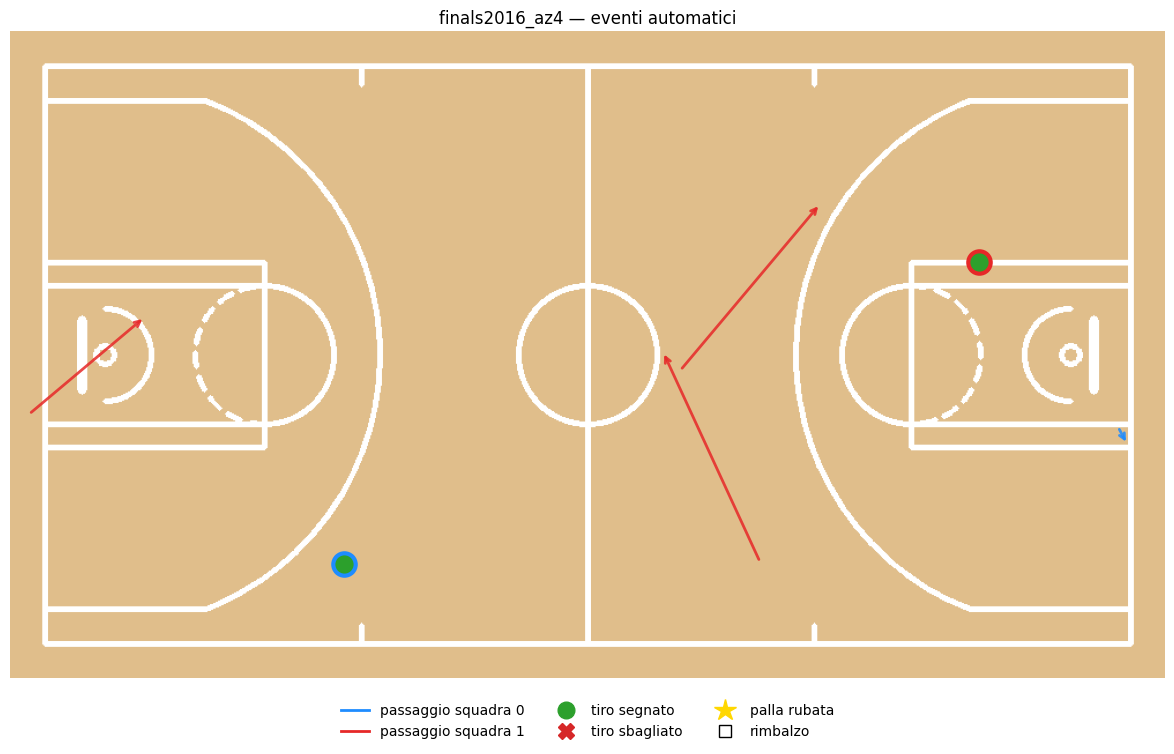

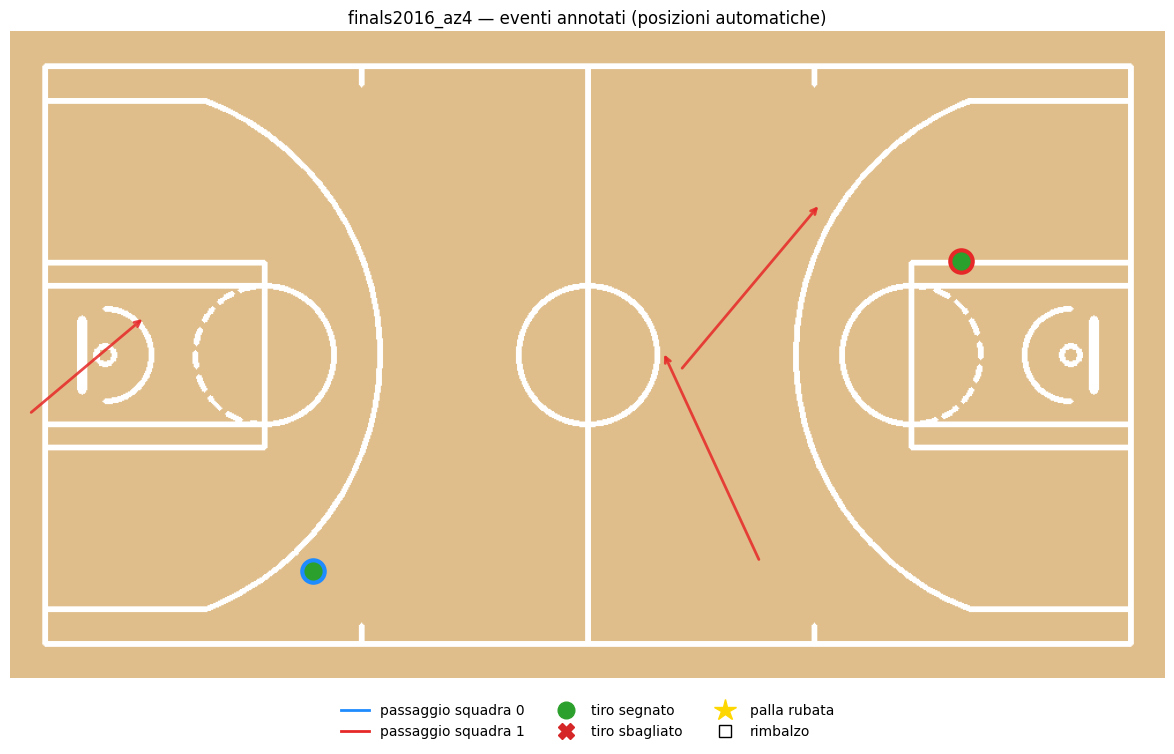

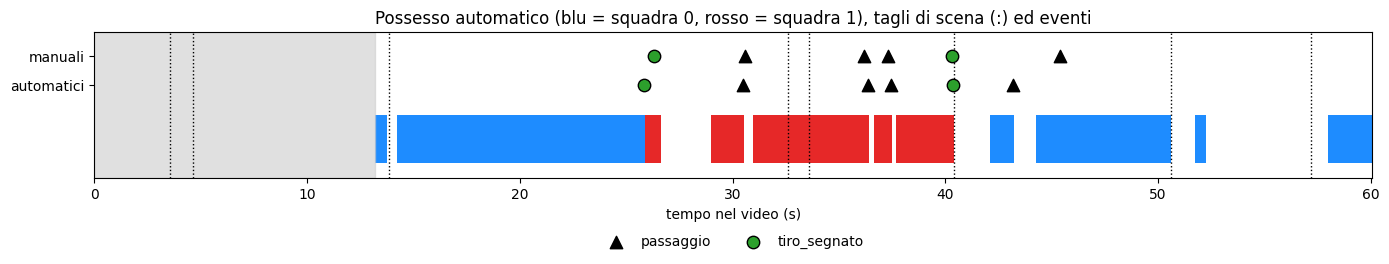

In [14]:
SCALE, PAD = 10, 30
base = draw_court(config=court, scale=SCALE, padding=PAD)
def to_map(x, y): return int(x * SCALE) + PAD, int(y * SCALE) + PAD
TEAM_RGB = {0: '#1e8cff', 1: '#e62828', -1: '#999999'}
from matplotlib.lines import Line2D

def lavagna(ev, title, path):
    fig, ax = plt.subplots(figsize=(13, 7.5)); ax.imshow(cv2.cvtColor(base, cv2.COLOR_BGR2RGB))
    for r in ev.itertuples():
        if np.isnan(r.x_ft) and r.tipo != 'palla_rubata': continue
        c = TEAM_RGB.get(int(r.team), '#999')
        if r.tipo == 'passaggio' and not np.isnan(r.x2_ft):
            ax.annotate('', xy=to_map(r.x2_ft, r.y2_ft), xytext=to_map(r.x_ft, r.y_ft), arrowprops=dict(arrowstyle='->', color=c, lw=2, alpha=.85))
        elif r.tipo == 'palla_rubata':
            xx, yy = (r.x2_ft, r.y2_ft) if not np.isnan(r.x2_ft) else (r.x_ft, r.y_ft)
            if not np.isnan(xx): ax.scatter(*to_map(xx, yy), marker='*', s=420, color='gold', edgecolor=c, linewidth=2, zorder=5)
        elif r.tipo == 'tiro_segnato': ax.scatter(*to_map(r.x_ft, r.y_ft), s=260, color='#2ca02c', edgecolor=c, linewidth=3, zorder=6)
        elif r.tipo == 'tiro_sbagliato': ax.scatter(*to_map(r.x_ft, r.y_ft), s=300, marker='X', color=c, edgecolor='k', linewidth=1.5, zorder=6)
        elif r.tipo == 'rimbalzo': ax.scatter(*to_map(r.x_ft, r.y_ft), s=120, marker='s', color='white', edgecolor=c, linewidth=2, zorder=4)
    leg = [Line2D([], [], color=TEAM_RGB[0], lw=2, label='passaggio squadra 0'), Line2D([], [], color=TEAM_RGB[1], lw=2, label='passaggio squadra 1'),
           Line2D([], [], marker='o', ls='', color='#2ca02c', ms=12, label='tiro segnato'), Line2D([], [], marker='X', ls='', color='#d62728', ms=12, label='tiro sbagliato'),
           Line2D([], [], marker='*', ls='', color='gold', ms=16, label='palla rubata'), Line2D([], [], marker='s', ls='', mfc='white', mec='k', ms=9, label='rimbalzo')]
    ax.legend(handles=leg, loc='upper center', bbox_to_anchor=(.5, -.02), ncol=3, frameon=False)
    ax.set_title(title); ax.axis('off'); fig.tight_layout(); fig.savefig(path, dpi=170); plt.show()

lavagna(ev_auto, f'{CLIP_ID} — eventi automatici', OUT / 'lavagna_automatica.png')
if len(ev_man): lavagna(ev_man, f'{CLIP_ID} — eventi annotati (posizioni automatiche)', OUT / 'lavagna_manuale.png')

fig, ax = plt.subplots(figsize=(14, 3))
for r in segs.itertuples():
    ax.barh(0, (r.end - r.start + 1) / FPS, left=r.start / FPS + START_S, color=TEAM_RGB.get(int(r.team), '#999'), height=.5)
for c in cuts: ax.axvline(c / FPS + START_S, color='k', ls=':', lw=1)
for a, b in ESCLUDI: ax.axvspan(a, b, color='#ccc', alpha=.6)
mk = {'passaggio': ('^', 'k'), 'palla_rubata': ('*', 'gold'), 'tiro_segnato': ('o', '#2ca02c'), 'tiro_sbagliato': ('X', '#d62728'), 'rimbalzo': ('s', 'w')}
for y0, ev, lab in [(.55, ev_auto, 'auto'), (.85, ev_man, 'manuale')]:
    for t, (m, c) in mk.items():
        e = ev[ev.tipo == t] if len(ev) else ev
        if len(e): ax.scatter(e.tempo_s, np.full(len(e), y0), marker=m, color=c, edgecolor='k', s=80, zorder=5, label=t if lab == 'auto' else None)
ax.set_yticks([.55, .85]); ax.set_yticklabels(['automatici', 'manuali']); ax.set_ylim(-.4, 1.1)
ax.set_xlabel('tempo nel video (s)'); ax.set_xlim(START_S, START_S + N / FPS)
ax.set_title('Possesso automatico (blu = squadra 0, rosso = squadra 1), tagli di scena (:) ed eventi')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(.5, -.3), frameon=False); fig.tight_layout(); fig.savefig(OUT / 'linea_del_tempo.png', dpi=160); plt.show()

## 9. Video diagnostico: ID, squadre, palla (grigio = candidati, giallo = accettata), possesso, eventi e lavagna

In [15]:
EV_VIDEO = ev_man if (VIDEO_EVENTS == 'manuale' and len(ev_man)) else ev_auto
BAR = 130                                                     # striscia delle statistiche sotto la lavagna
mh = H_IMG; mw = int(base.shape[1] * mh / (base.shape[0] + BAR)); out_w = W_IMG + mw; out_w += out_w % 2
vw = cv2.VideoWriter(str(OUT / 'diagnostica_raw.mp4'), cv2.VideoWriter_fourcc(*'mp4v'), FPS, (out_w, H_IMG))
trk_by = dict(tuple(tracks.groupby('frame')))
LABEL = {'passaggio': 'PASSAGGIO', 'palla_rubata': 'PALLA RUBATA', 'tiro_segnato': 'TIRO SEGNATO', 'tiro_sbagliato': 'TIRO SBAGLIATO', 'rimbalzo': 'RIMBALZO'}
TEAM_NAME = {0: 'BLU', 1: 'ROSSI', -1: '?'}
ev_col = lambda team: TEAM_COLORS.get(int(team), (200, 200, 200))
cut_set = set(cuts)

def stats_bar(fi, width):
    # intestazioni su due righe e centrate in colonne uguali, così non si sovrappongono
    bar = np.full((BAR, width, 3), 245, np.uint8); e = EV_VIDEO[EV_VIDEO.frame <= fi]
    cols = [('TIRI', 'segn./tent.'), ('DA 3', 'segn./tent.'), ('RIMBALZI', ''), ('PALLE', 'RUBATE')] + ([('PASSAGGI', '')] if SHOW_PASSES else [])
    x0 = 110; cw = (width - x0) // len(cols); F_ = cv2.FONT_HERSHEY_SIMPLEX
    def center(txt, j, y, sc, col, th):
        (tw, _), _ = cv2.getTextSize(txt, F_, sc, th); cv2.putText(bar, txt, (x0 + j * cw + (cw - tw) // 2, y), F_, sc, col, th)
    for j, (h1, h2) in enumerate(cols):
        center(h1, j, 26, .6, (60, 60, 60), 2)
        if h2: center(h2, j, 48, *((.6, (60, 60, 60), 2) if h2.isupper() else (.45, (110, 110, 110), 1)))   # 'RUBATE' come titolo, 'segn./tent.' come nota
    for k, team in enumerate([0, 1]):
        y = 84 + 32 * k; et = e[e.team == team]
        cv2.putText(bar, TEAM_NAME[team], (12, y), F_, .75, ev_col(team), 2)
        tiri = et.tipo.str.startswith('tiro').sum(); segn = (et.tipo == 'tiro_segnato').sum()
        t3 = et.tipo.str.startswith('tiro') & et.dettaglio.astype(str).str.contains('da 3')
        vals = [f'{segn}/{tiri}', f'{(t3 & (et.tipo == "tiro_segnato")).sum()}/{t3.sum()}', str((et.tipo == 'rimbalzo').sum()), str((et.tipo == 'palla_rubata').sum())] + ([str((et.tipo == 'passaggio').sum())] if SHOW_PASSES else [])
        for jj, v in enumerate(vals): center(v, jj, y, .85, ev_col(team), 2)
    return bar

for fi, f in frames_iter(desc='video'):
    img = f.copy(); mp = base.copy()
    if excluded[fi]:
        cv2.putText(img, 'ESCLUSO', (20, 60), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 0, 255), 3)
    past = EV_VIDEO[EV_VIDEO.frame <= fi]
    # tiri, rimbalzi e palle rubate restano per tutta la clip, nel colore della squadra
    for r in past[past.tipo.isin(['tiro_segnato', 'tiro_sbagliato', 'rimbalzo', 'palla_rubata'])].itertuples():
        xx, yy = (r.x2_ft, r.y2_ft) if (r.tipo == 'palla_rubata' and not np.isnan(r.x2_ft)) else (r.x_ft, r.y_ft)
        if np.isnan(xx): continue
        p = to_map(xx, yy); c = ev_col(r.team)
        if r.tipo == 'tiro_segnato': cv2.circle(mp, p, 12, c, 4)
        elif r.tipo == 'tiro_sbagliato': cv2.drawMarker(mp, p, c, cv2.MARKER_TILTED_CROSS, 24, 4)
        elif r.tipo == 'rimbalzo': cv2.rectangle(mp, (p[0] - 9, p[1] - 9), (p[0] + 9, p[1] + 9), c, 3)
        else: cv2.drawMarker(mp, p, c, cv2.MARKER_STAR, 26, 3)
    # passaggi: freccia che sparisce dopo PASS_SHOW_S
    if SHOW_PASSES:
        for r in past[(past.frame > fi - PASS_SHOW_S * FPS) & (past.tipo == 'passaggio')].itertuples():
            if np.isnan(r.x_ft) or np.isnan(r.x2_ft): continue
            cv2.arrowedLine(mp, to_map(r.x_ft, r.y_ft), to_map(r.x2_ft, r.y2_ft), ev_col(r.team), 3, tipLength=.08)
    holder = poss[fi]
    for r in trk_by.get(fi, pd.DataFrame()).itertuples():
        c = TEAM_COLORS.get(int(r.team), (160, 160, 160)); th = 4 if r.track_id == holder else 2
        cv2.rectangle(img, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), c, th)
        cv2.putText(img, str(r.track_id), (int(r.x1), max(14, int(r.y1) - 4)), cv2.FONT_HERSHEY_SIMPLEX, .55, c, 2)
        if not np.isnan(r.xs_ft):
            p = to_map(r.xs_ft, r.ys_ft); cv2.circle(mp, p, 9, c, -1); cv2.circle(mp, p, 9, (0, 0, 0), 1)
            if r.track_id == holder: cv2.circle(mp, p, 14, (0, 200, 255), 3)
    for cx, cy, cf in cand_by.get(fi, []):
        cv2.circle(img, (int(cx), int(cy)), 6, (150, 150, 150), 1)
    if not np.isnan(ball.bx[fi]):
        cv2.circle(img, (int(ball.bx[fi]), int(ball.by[fi])), 9, (0, 220, 255), 3)
    recent = past[past.frame > fi - 1.5 * FPS]
    if not SHOW_PASSES: recent = recent[recent.tipo != 'passaggio']
    for k, r in enumerate(recent.itertuples()):              # scritta dell'evento nel colore della squadra
        txt = LABEL.get(r.tipo, r.tipo) + ' ' + TEAM_NAME.get(int(r.team), '') + (f'  {r.dettaglio}' if r.tipo.startswith('tiro') and isinstance(r.dettaglio, str) else '')
        cv2.putText(img, txt, (12, 34 + 30 * k), cv2.FONT_HERSHEY_SIMPLEX, .8, (0, 0, 0), 6)
        cv2.putText(img, txt, (12, 34 + 30 * k), cv2.FONT_HERSHEY_SIMPLEX, .8, ev_col(r.team), 2)
    t = f'{fi / FPS + START_S:6.1f} s'
    cv2.putText(img, t, (W_IMG - 170, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 0), 6)
    cv2.putText(img, t, (W_IMG - 170, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
    if fi in cut_set: cv2.rectangle(img, (0, 0), (W_IMG - 1, H_IMG - 1), (0, 0, 255), 12)
    if Hs[fi] is None: cv2.putText(mp, 'campo non visibile', (10, 22), cv2.FONT_HERSHEY_SIMPLEX, .6, (0, 0, 255), 2)
    panel = np.vstack([mp, stats_bar(fi, mp.shape[1])])
    canvas = np.zeros((H_IMG, out_w, 3), np.uint8); canvas[:, :W_IMG] = img; canvas[:, W_IMG:W_IMG + mw] = cv2.resize(panel, (mw, mh))
    vw.write(canvas)
vw.release()
subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', str(OUT / 'diagnostica_raw.mp4'), '-c:v', 'libx264', '-crf', '24',
                '-pix_fmt', 'yuv420p', str(OUT / 'diagnostica.mp4')], check=True)
(OUT / 'diagnostica_raw.mp4').unlink()
print('Video:', OUT / 'diagnostica.mp4')

video:   0%|          | 0/1800 [00:00<?, ?it/s]

Video: /content/drive/MyDrive/Tesi_Basket/events_nba/finals2016_az4/diagnostica.mp4


## 10. Valutazione degli eventi automatici contro quelli annotati

In [16]:
def match(pred_t, ref_t, tol):
    pairs = sorted((abs(p - r), i, j) for i, p in enumerate(pred_t) for j, r in enumerate(ref_t) if abs(p - r) <= tol)
    up, ur = set(), set()
    for _, i, j in pairs:
        if i not in up and j not in ur: up.add(i); ur.add(j)
    return len(up)
if len(man):
    groups = {t: [t] for t in ['passaggio', 'palla_rubata', 'tiro_segnato', 'tiro_sbagliato', 'rimbalzo']}
    groups['tiro (tentativo)'] = ['tiro_segnato', 'tiro_sbagliato']
    rows = []
    for name, types in groups.items():
        p = ev_auto[ev_auto.tipo.isin(types)].tempo_s.values; r = man[man.tipo.isin(types)].tempo_s.values
        tp = match(p, r, EVENT_TOL_S)
        rows.append({'tipo': name, 'rilevati': len(p), 'veri': len(r), 'corretti': tp,
                     'precisione': tp / len(p) if len(p) else np.nan, 'richiamo': tp / len(r) if len(r) else np.nan})
    val = pd.DataFrame(rows).round(2); val.insert(0, 'clip', CLIP_ID)
    val.to_csv(OUT / 'valutazione_eventi.csv', index=False); display(val)
else:
    print('Nessun evento annotato per questa clip: compila', MANUAL.name, 'e riesegui le sezioni 7-10.')

summary = {'clip': CLIP_ID, 'secondi': round(N / FPS, 1), 'tagli_scena': len(cuts),
           'palla_candidati_%': round(100 * len(cand_by) / max(1, (~excluded).sum()), 1),
           'palla_accettata_%': round(100 * np.isfinite(acc[:, 0]).sum() / max(1, (~excluded).sum()), 1),
           'tracce': int(tracks.track_id.nunique()), 'segmenti_possesso': len(segs),
           'eventi_automatici': ev_auto.tipo.value_counts().to_dict(), 'eventi_manuali': len(ev_man)}
(OUT / 'riepilogo.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False)); print(json.dumps(summary, indent=2, ensure_ascii=False))

,clip,tipo,rilevati,veri,corretti,precisione,richiamo
0,finals2016_az4,passaggio,4,4,3,0.75,0.75
1,finals2016_az4,palla_rubata,0,0,0,NaN,NaN
2,finals2016_az4,tiro_segnato,2,2,2,1.00,1.00
3,finals2016_az4,tiro_sbagliato,0,0,0,NaN,NaN
4,finals2016_az4,rimbalzo,0,0,0,NaN,NaN
5,finals2016_az4,tiro (tentativo),2,2,2,1.00,1.00


{
  "clip": "finals2016_az4",
  "secondi": 60.1,
  "tagli_scena": 8,
  "palla_candidati_%": 79.8,
  "palla_accettata_%": 64.6,
  "tracce": 95,
  "segmenti_possesso": 14,
  "eventi_automatici": {
    "passaggio": 4,
    "tiro_segnato": 2
  },
  "eventi_manuali": 6
}
